In [1]:

from google.colab import files

uploaded = files.upload()


Saving ppe-best-step10.zip to ppe-best-step10.zip


In [2]:

import os
import zipfile

ZIP_PATH = "/content/ppe-best-step10.zip"
ADAPTER_PATH = "/content/ppe-best-step10"

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(ADAPTER_PATH)

print("Extracted files:")
print(os.listdir(ADAPTER_PATH))


Extracted files:
['optimizer.pt', 'training_args.bin', 'README.md', 'rng_state.pth', 'scheduler.pt', 'tokenizer_config.json', 'tokenizer.json', 'adapter_model.safetensors', 'processor_config.json', 'adapter_config.json', 'scaler.pt', 'chat_template.jinja', 'trainer_state.json']


In [3]:

%pip install -q -U transformers peft accelerate bitsandbytes qwen-vl-utils


In [4]:

import torch
from transformers import (
    AutoProcessor,
    BitsAndBytesConfig,
    Qwen2_5_VLForConditionalGeneration,
)
from peft import PeftModel

BASE_MODEL = "Qwen/Qwen2.5-VL-3B-Instruct"
ADAPTER_PATH = "/content/ppe-best-step10"

# Use 4-bit quantization to fit the model on the T4 GPU.
quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

processor = AutoProcessor.from_pretrained(BASE_MODEL)

base_model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    BASE_MODEL,
    quantization_config=quant_config,
    torch_dtype=torch.float16,
    device_map="auto",
)

model = PeftModel.from_pretrained(base_model, ADAPTER_PATH)
model.eval()

print("Base model loaded:", BASE_MODEL)
print("Saved adapter attached:", ADAPTER_PATH)
print("Training is not being performed.")


preprocessor_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.37k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/5.70k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/216 [00:00<?, ?B/s]

Base model loaded: Qwen/Qwen2.5-VL-3B-Instruct
Saved adapter attached: /content/ppe-best-step10
Training is not being performed.


In [5]:

from google.colab import files

uploaded = files.upload()  # Select your CCTV video, e.g. .mp4 or .avi

VIDEO_PATH = next(iter(uploaded))
print("Video loaded:", VIDEO_PATH)


Saving cctv_worker_remove_hat.mp4 to cctv_worker_remove_hat.mp4
Video loaded: cctv_worker_remove_hat.mp4


In [6]:

import cv2
import json
import re
import torch
import numpy as np
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display, Video

# VIDEO_PATH should be set by your previous upload cell.
OUTPUT_PATH = "/content/ppe_annotated.mp4"
FRAME_INTERVAL = 1.0  # seconds between processed frames

cap = cv2.VideoCapture(VIDEO_PATH)
if not cap.isOpened():
    raise ValueError(f"Cannot open video: {VIDEO_PATH}")

fps = cap.get(cv2.CAP_PROP_FPS) or 25
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
duration = total_frames / fps

# Write at original FPS, holding each prediction until the next sampled frame.
writer = cv2.VideoWriter(
    OUTPUT_PATH,
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (width, height),
)

prompt = (
    "Detect visible PPE objects and PPE compliance. Classes: Helmet, "
    "NoHelmet, Vest, NoVest. Return only JSON: "
    '{"objects":[{"class":"Helmet","bbox":[cx,cy,w,h]}]}. '
    "Bounding boxes must be normalized to 0-1 as "
    "[center_x, center_y, width, height]. "
    "Only report objects you can visually identify. "
    "If uncertain, return an empty objects list."
)

def get_detections(pil_image):
    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": pil_image},
            {"type": "text", "text": prompt},
        ],
    }]

    chat_text = processor.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )
    inputs = processor(
        text=[chat_text], images=[pil_image], return_tensors="pt"
    ).to(model.device)

    with torch.inference_mode():
        generated = model.generate(
            **inputs, max_new_tokens=256, do_sample=False
        )

    new_tokens = generated[:, inputs.input_ids.shape[1]:]
    response = processor.batch_decode(
        new_tokens, skip_special_tokens=True
    )[0]

    match = re.search(r"\{.*\}", response, re.DOTALL)
    if not match:
        return []

    try:
        objects = json.loads(match.group(0)).get("objects", [])
    except (json.JSONDecodeError, AttributeError):
        return []

    valid = []
    for obj in objects:
        cls = str(obj.get("class", obj.get("label", ""))).replace(" ", "").lower()
        box = obj.get("bbox", obj.get("box"))
        aliases = {
            "helmet": "Helmet", "nohelmet": "NoHelmet",
            "vest": "Vest", "novest": "NoVest",
        }
        if cls not in aliases or not isinstance(box, list) or len(box) != 4:
            continue
        try:
            cx, cy, bw, bh = map(float, box)
        except (ValueError, TypeError):
            continue
        if not all(np.isfinite([cx, cy, bw, bh])):
            continue
        if not (0 <= cx <= 1 and 0 <= cy <= 1 and 0 < bw <= 1 and 0 < bh <= 1):
            continue
        valid.append((aliases[cls], cx, cy, bw, bh))
    return valid

# Sample at FRAME_INTERVAL seconds and reuse each result between samples.
sample_frames = max(1, round(fps * FRAME_INTERVAL))
cached_detections = []
frame_index = 0

try:
    with tqdm(total=total_frames, desc="Annotating video") as progress:
        while True:
            ok, frame = cap.read()
            if not ok:
                break

            if frame_index % sample_frames == 0:
                pil_image = Image.fromarray(
                    cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                )
                try:
                    cached_detections = get_detections(pil_image)
                except Exception as e:
                    print(f"\nInference failed at frame {frame_index}: {e}")
                    cached_detections = []

            for cls, cx, cy, bw, bh in cached_detections:
                x1 = max(0, int((cx - bw / 2) * width))
                y1 = max(0, int((cy - bh / 2) * height))
                x2 = min(width - 1, int((cx + bw / 2) * width))
                y2 = min(height - 1, int((cy + bh / 2) * height))
                if x2 <= x1 or y2 <= y1:
                    continue

                color = (0, 200, 0) if cls in ("Helmet", "Vest") else (0, 0, 255)
                cv2.rectangle(frame, (x1, y1), (x2, y2), color, 2)
                cv2.putText(
                    frame, cls, (x1, max(25, y1 - 8)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, color, 2,
                )

            writer.write(frame)
            frame_index += 1
            progress.update(1)
finally:
    cap.release()
    writer.release()

print("Annotated video saved:", OUTPUT_PATH)
display(Video(OUTPUT_PATH, embed=True, width=800))


Annotating video:   0%|          | 0/240 [00:00<?, ?it/s]

Annotated video saved: /content/ppe_annotated.mp4


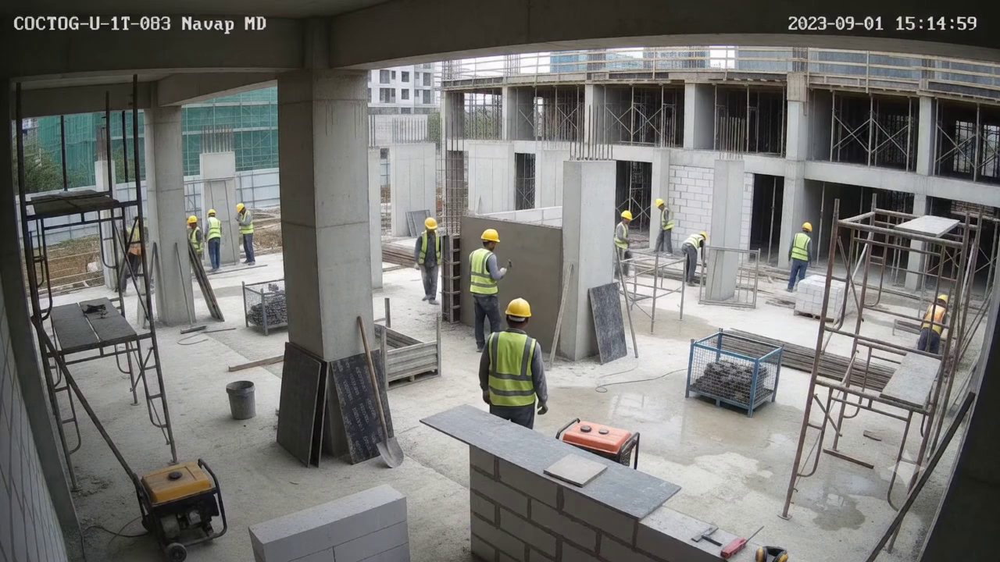

RAW MODEL PREDICTION:
```json
[
    {
        "class": "Helmet",
        "bbox": [
            [240, 276, 258, 293],
            [267, 270, 280, 283],
            [303, 261, 317, 275],
            [546, 281, 564, 297],
            [619, 296, 644, 312],
            [649, 385, 685, 411],
            [799, 272, 815, 286],
            [844, 257, 859, 271],
            [899, 300, 912, 313],
            [1030, 287, 1046, 301],
            [1199, 380, 1219, 400]
        ]
   

PARSED DETECTIONS:
[]


In [7]:

import cv2
from PIL import Image
import torch

VIDEO_PATH = "/content/cctv_worker_remove_hat.mp4"

cap = cv2.VideoCapture(VIDEO_PATH)
ok, frame = cap.read()
cap.release()

if not ok:
    raise RuntimeError("Could not read the first video frame.")

image = Image.fromarray(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
display(image)

messages = [{
    "role": "user",
    "content": [
        {"type": "image", "image": image},
        {"type": "text", "text": prompt},
    ],
}]

text = processor.apply_chat_template(
    messages, tokenize=False, add_generation_prompt=True
)

inputs = processor(
    text=[text], images=[image], return_tensors="pt"
).to(model.device)

with torch.inference_mode():
    output_ids = model.generate(
        **inputs, max_new_tokens=256, do_sample=False
    )

new_tokens = output_ids[:, inputs.input_ids.shape[1]:]
raw_prediction = processor.batch_decode(
    new_tokens, skip_special_tokens=True
)[0]

print("RAW MODEL PREDICTION:")
print(raw_prediction)
print("\nPARSED DETECTIONS:")
print(get_detections(image))


## 00:00


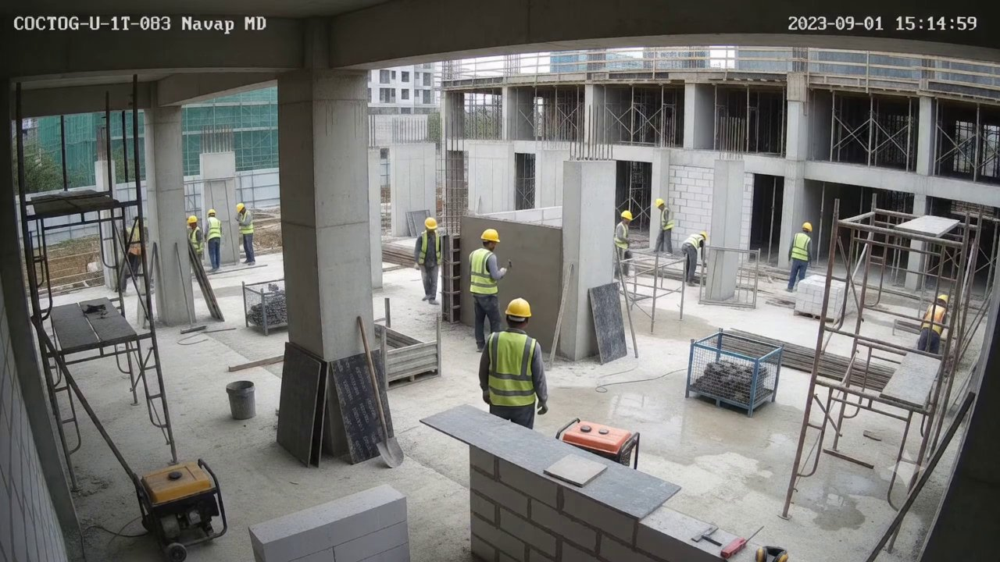

## 00:02


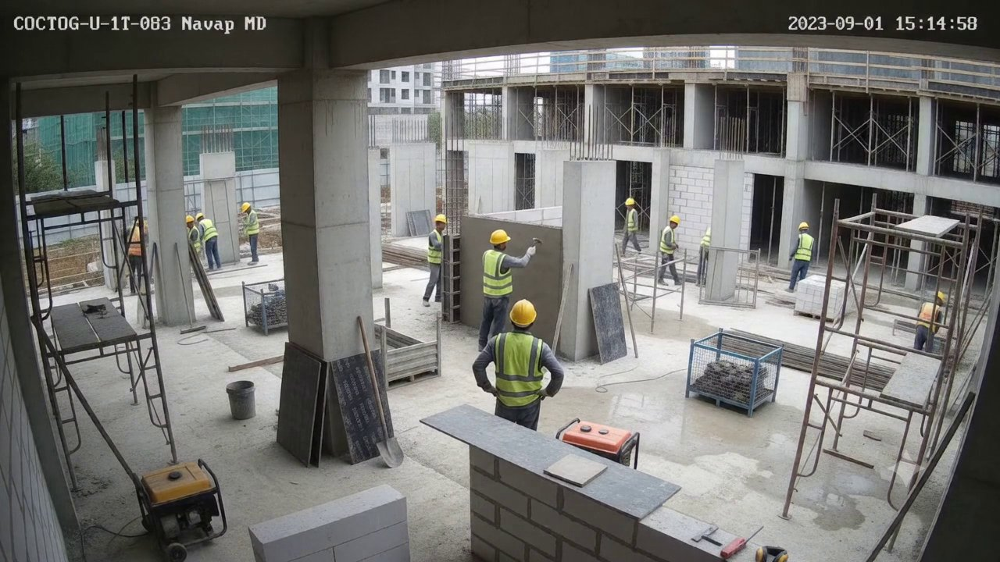

## 00:04


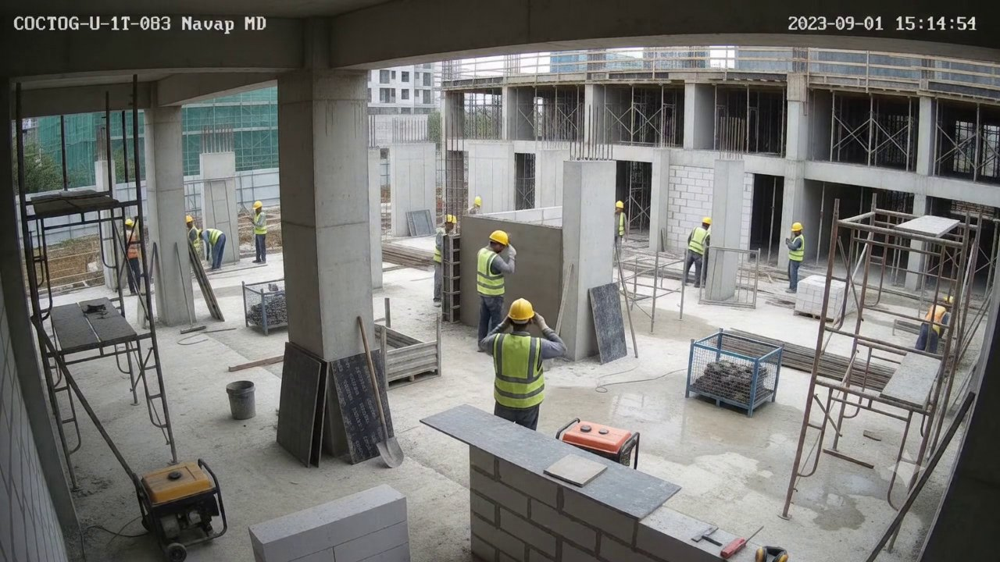

## 00:06


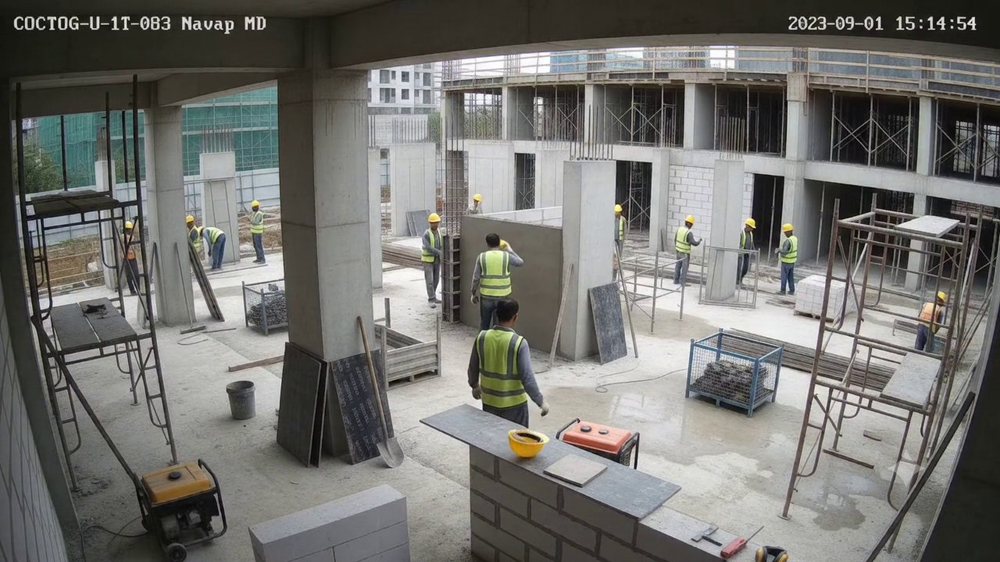

## 00:08


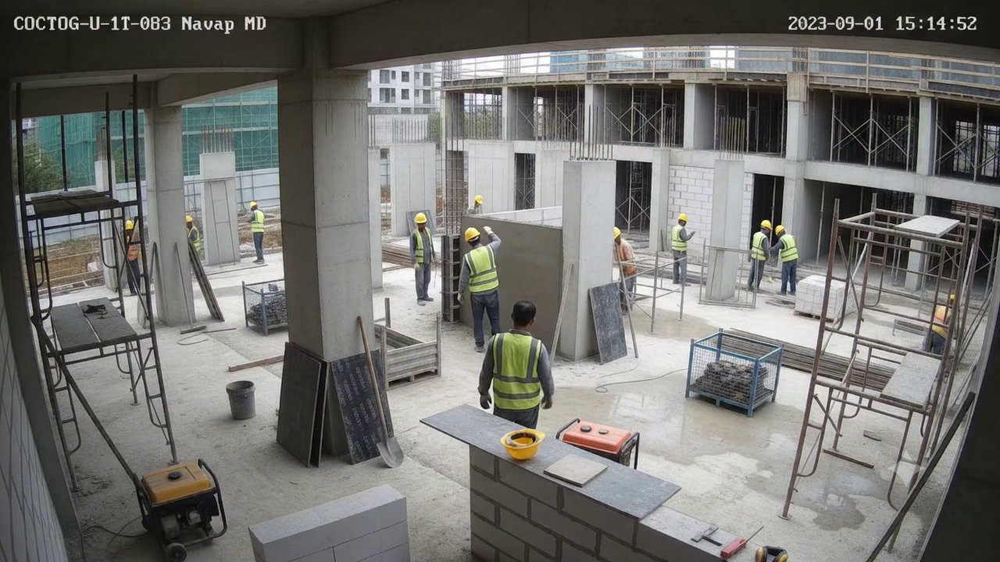

In [9]:

from IPython.display import display, Markdown
from PIL import Image
import cv2

cap = cv2.VideoCapture(VIDEO_PATH)

for item in results:
    seconds = int(item["timestamp"].split(":")[0]) * 60 + int(
        item["timestamp"].split(":")[1]
    )

    cap.set(cv2.CAP_PROP_POS_MSEC, seconds * 1000)
    ok, frame = cap.read()

    if not ok:
        continue

    frame_image = Image.fromarray(
        cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    )

    display(Markdown(f"## {item['timestamp']}"))

    # Show the actual frame and its paired description side by side.
    from IPython.display import HTML
    import io, base64

    buffer = io.BytesIO()
    frame_image.save(buffer, format="JPEG", quality=85)
    encoded = base64.b64encode(buffer.getvalue()).decode("ascii")

    description = item["description"]
    import html
    description_html = html.escape(description).replace("\n", "<br>")

    display(HTML(f"""
    <div style="display:flex;gap:18px;align-items:flex-start;
                margin-bottom:24px;width:100%;">
      <div style="flex:1;min-width:0;">
        <img src="data:image/jpeg;base64,{encoded}"
             style="width:100%;height:auto;border-radius:8px;">
      </div>
      <div style="flex:1;min-width:0;white-space:normal;
                  line-height:1.6;">
        {description_html}
      </div>
    </div>
    """))

cap.release()


In [10]:

def describe_frame(image):
    prompt = """
You are analyzing construction-site CCTV footage for PPE safety violations.
Follow these instructions carefully for THIS FRAME ONLY.

Your main task is to identify PPE violations, not to produce a general
description of the construction site.

STEP 1 — Inspect workers individually:
- Examine every visible worker separately, including workers in the
  background.
- Do not assume all workers follow the same safety practices.
- Do not conclude that all workers are compliant merely because some
  workers wear helmets and reflective vests.
- Inspect each worker's head for a visibly worn safety helmet.
- Inspect each worker's torso for a visibly worn reflective safety vest.
- A helmet resting on a wall, held in a hand, or placed nearby does
  NOT count as a helmet being worn.
- A vest or helmet must be visibly identifiable before you report it.

STEP 2 — Determine compliance:
- Report a helmet violation only when a worker's uncovered head is
  sufficiently visible to support that conclusion.
- Report a vest violation only when the worker's torso is sufficiently
  visible and no reflective safety vest is worn.
- If a worker is too small, obscured, or unclear, label their PPE status
  as UNCERTAIN rather than assuming compliance.
- Never claim that every worker is compliant unless the frame supports it.

STEP 3 — Return this structured text:
Overall status: COMPLIANT, VIOLATION, MIXED, or UNCERTAIN.

Worker observations:
For each distinguishable worker or group of workers whose status can
be assessed, state:
- Approximate location in the frame.
- Helmet status: WORN, MISSING, or UNCERTAIN.
- Vest status: WORN, MISSING, or UNCERTAIN.
- Visible evidence supporting the assessment.

Safety violations:
Describe each supported violation. If none can be confirmed, say so.

Recommended action:
Give a practical safety action for confirmed violations. If evidence
is insufficient, recommend closer inspection instead of guessing.

IMPORTANT:
Base conclusions on visual evidence in this frame.
Do not invent workers, PPE items, or violations.
Do not claim to compare with previous frames.
Be concise but specific. Avoid generic statements such as "all workers
are wearing PPE" unless each visible worker has been assessed.
"""

    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": prompt},
        ],
    }]

    chat_text = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )

    inputs = processor(
        text=[chat_text],
        images=[image],
        return_tensors="pt",
    ).to(model.device)

    with torch.inference_mode():
        output = model.generate(
            **inputs,
            max_new_tokens=320,
            do_sample=False,
        )

    new_tokens = output[:, inputs.input_ids.shape[1]:]

    return processor.batch_decode(
        new_tokens,
        skip_special_tokens=True,
    )[0].strip()


In [12]:

prompt = """
You are a construction-site safety auditor analyzing one CCTV frame.
Your priority is to find actual PPE violations, not to assume compliance.

Inspect the image carefully from left to right and foreground to background.

For EACH visible worker:
1. Locate the worker approximately (for example: foreground center,
   far left, background right).
2. Assess whether a safety helmet is visibly worn on their head.
3. Assess whether a reflective safety vest is visibly worn on their torso.
4. Describe the specific visual evidence for each assessment.

Rules:
- A yellow object near a worker is not proof that it is worn on the head.
- A helmet held, stored, or resting nearby does not count as worn.
- Do not infer helmet use from clothing, location, or other workers.
- Do not group all workers into one observation.
- If a worker's head or torso is too small or obscured, mark that
  item UNCERTAIN.
- Never claim all workers are compliant unless each visible worker
  has sufficient visual evidence.
- Do not invent violations either.

Return exactly these sections:

OVERALL STATUS: COMPLIANT / VIOLATION / MIXED / UNCERTAIN

INDIVIDUAL WORKERS:
Worker 1 — approximate location
Helmet: WORN / MISSING / UNCERTAIN
Vest: WORN / MISSING / UNCERTAIN
Evidence: specific visible details

(Repeat for each distinguishable worker.)

CONFIRMED VIOLATIONS:
List each confirmed violation and its visual evidence.
If none can be confirmed, say so.

UNCERTAINTIES:
Identify workers whose PPE cannot be assessed reliably.

RECOMMENDED ACTION:
Give a practical action based on the evidence.

Avoid generic statements such as "all workers are wearing PPE."
Do not claim to compare with earlier frames.
"""


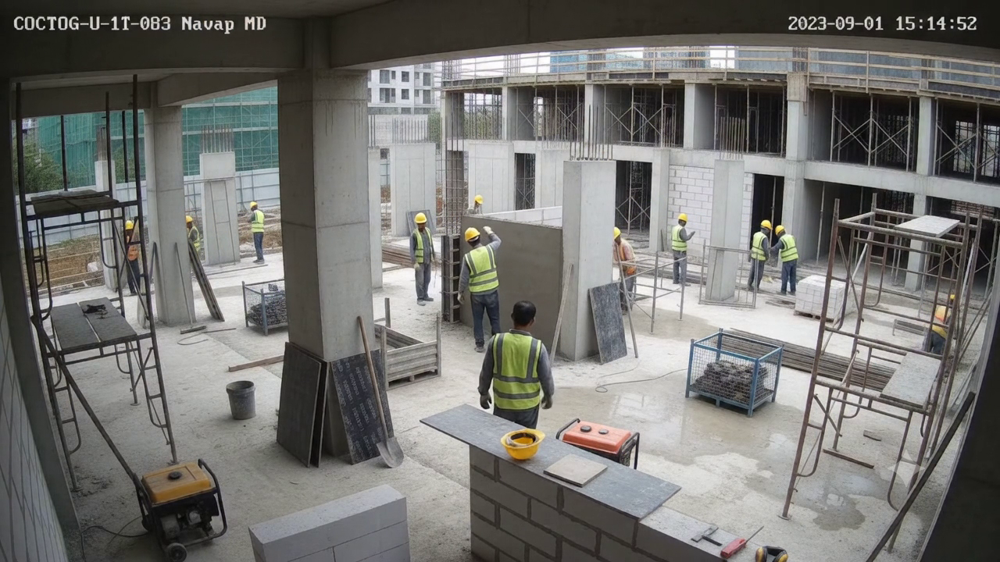

FINE-TUNED MODEL PREDICTION:

**Overall status:** COMPLIANT

**Worker observations:**

1. **Location:** Left foreground
   - **Helmet status:** WORN
   - **Vest status:** WORN
   - **Visible evidence:** Workers are wearing helmets and reflective vests.

2. **Location:** Center-left
   - **Helmet status:** WORN
   - **Vest status:** WORN
   - **Visible evidence:** Workers are wearing helmets and reflective vests.

3. **Location:** Center-right
   - **Helmet status:** WORN
   - **Vest status:** WORN
   - **Visible evidence:** Workers are wearing helmets and reflective vests.

4. **Location:** Right-center
   - **Helmet status:** WORN
   - **Vest status:** WORN
   - **Visible evidence:** Workers are wearing helmets and reflective vests.

5. **Location:** Background left
   - **Helmet status:** WORN
   - **Vest status:** WORN
   - **Visible evidence:** Workers are wearing helmets and reflective vests.

6. **Location:** Background center
   - **Helmet status:** WORN
   - **Vest status:** WO

In [13]:

cap = cv2.VideoCapture(VIDEO_PATH)
cap.set(cv2.CAP_PROP_POS_MSEC, 8000)
ok, frame = cap.read()
cap.release()

if not ok:
    print("Could not read frame at 00:08.")
else:
    image = Image.fromarray(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    display(image)

    prediction = describe_frame(image)
    print("FINE-TUNED MODEL PREDICTION:\n")
    print(prediction)


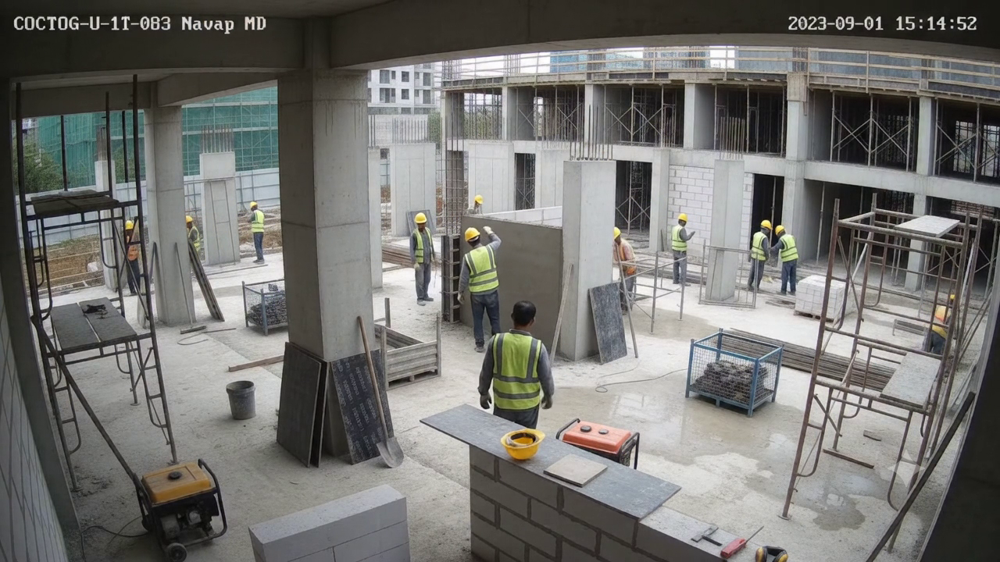

FRAME TIMESTAMP: 00:08

FINE-TUNED MODEL ASSESSMENT:

**Objectively Described Construction-Site CCTV Frame:**

The image shows a construction site with several workers engaged in various tasks. The workers are wearing safety helmets and reflective safety vests. Here is a detailed description of each worker:

1. **Worker 1:** Positioned near the left side of the image, wearing a helmet and a reflective safety vest. The helmet appears to be securely placed on their head.
2. **Worker 2:** Located towards the center-left of the image, also wearing a helmet and a reflective safety vest. The helmet is clearly visible and secured.
3. **Worker 3:** Near the center-right of the image, wearing a helmet and a reflective safety vest. The helmet is visible and secure.
4. **Worker 4:** Positioned towards the right-center of the image, wearing a helmet and a reflective safety vest. The helmet is visible and secure.
5. **Worker 5:** Near the right edge of the image, wearing a helmet and a reflective s

In [15]:

import cv2
import torch
from PIL import Image
from IPython.display import display

# 1. Read the video frame at 00:08
VIDEO_PATH = "/content/cctv_worker_remove_hat.mp4"
TIMESTAMP_SECONDS = 8

cap = cv2.VideoCapture(VIDEO_PATH)
cap.set(cv2.CAP_PROP_POS_MSEC, TIMESTAMP_SECONDS * 1000)
ok, frame = cap.read()
cap.release()

if not ok:
    raise RuntimeError(f"Could not read video frame at {TIMESTAMP_SECONDS}s.")

image = Image.fromarray(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
display(image)

# 2. Prompt: inspect individual workers, not the scene generally

prompt = """
Describe this construction-site CCTV frame objectively.

Assess the visible workers' safety helmets and reflective safety vests.
Do not assume that a worker is compliant or violating safety rules.

For each clearly distinguishable worker:
- Give an approximate location in the frame.
- State whether a helmet is visibly being worn, visibly missing,
  or cannot be determined.
- State whether a reflective safety vest is visibly being worn,
  visibly missing, or cannot be determined.
- Explain the visual evidence briefly.

A helmet resting on a wall or held in a hand is not being worn.
Do not confuse a yellow object with a helmet on someone's head.
Do not infer that PPE is missing just because it is hard to see.
Do not infer compliance from other workers.
If the image does not provide enough evidence, report UNCERTAIN.

Finish with:
Overall assessment: COMPLIANT, VIOLATION, MIXED, or UNCERTAIN.
Confirmed violations: only those supported by clear visual evidence.
Recommended action: a practical action based on the evidence.

Do not invent observations or claim certainty when details are unclear.
"""



# 3. Prepare the frame for the already-loaded fine-tuned Qwen model
messages = [{
    "role": "user",
    "content": [
        {"type": "image", "image": image},
        {"type": "text", "text": prompt},
    ],
}]

chat_text = processor.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True,
)

inputs = processor(
    text=[chat_text],
    images=[image],
    return_tensors="pt",
).to(model.device)

# 4. Inference only — no training or weight updates
with torch.inference_mode():
    output = model.generate(
        **inputs,
        max_new_tokens=400,
        do_sample=False,
    )

new_tokens = output[:, inputs.input_ids.shape[1]:]
prediction = processor.batch_decode(
    new_tokens,
    skip_special_tokens=True,
)[0].strip()

# 5. Display the result
print(f"FRAME TIMESTAMP: 00:08\n")
print("FINE-TUNED MODEL ASSESSMENT:\n")
print(prediction)


In [16]:

import cv2
import torch
from PIL import Image
from tqdm.auto import tqdm

VIDEO_PATH = "/content/cctv_worker_remove_hat.mp4"
FRAME_INTERVAL = 2  # Analyze one frame every 2 seconds
MAX_NEW_TOKENS = 300

# Neutral, evidence-based reasoning prompt
prompt = """
You are analyzing a construction-site CCTV frame for workplace PPE safety.

Analyze the CURRENT FRAME carefully. Base every conclusion on visible
evidence. Do not assume that workers are compliant or violating rules.

For the workers visible in this frame:
1. Describe the scene briefly.
2. Examine visible workers individually where possible, from foreground
   to background.
3. Assess whether a safety helmet is visibly worn on each worker's head.
4. Assess whether a reflective safety vest is visibly worn on each
   worker's torso.
5. Explain the specific visual evidence supporting each assessment.
6. If a worker or PPE item is too small, obscured, or ambiguous, state
   UNCERTAIN instead of guessing.

Important distinctions:
- A helmet nearby, held in a hand, or resting on a wall is not being worn.
- Do not mistake a yellow object for a helmet on someone's head.
- Do not infer missing PPE merely because it is difficult to see.
- Do not infer compliance because other workers are wearing PPE.
- Do not claim every worker is compliant without sufficient evidence.
- Do not invent workers, actions, or objects.
- Analyze this frame independently; do not claim to remember or compare
  previous frames.

Return these sections:

SCENE DESCRIPTION:
A concise description of the visible activity.

WORKER OBSERVATIONS:
For each distinguishable worker, give an approximate image location,
helmet status (WORN / MISSING / UNCERTAIN), vest status
(WORN / MISSING / UNCERTAIN), and supporting visual evidence.
Avoid repeating identical generic observations for every worker.

OVERALL ASSESSMENT:
COMPLIANT, VIOLATION, MIXED, or UNCERTAIN.
Explain why, based on the observations above.

CONFIRMED VIOLATIONS:
List only violations supported by visible evidence. If none can be
confirmed, say so; do not automatically declare the site compliant.

UNCERTAINTIES:
State what could not be assessed reliably.

RECOMMENDED ACTION:
Recommend a practical action based on confirmed violations or
uncertainties. Do not recommend unnecessary action when evidence
does not support it.
"""

def describe_frame(image):
    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": prompt},
        ],
    }]

    chat_text = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )

    inputs = processor(
        text=[chat_text],
        images=[image],
        return_tensors="pt",
    ).to(model.device)

    with torch.inference_mode():
        output = model.generate(
            **inputs,
            max_new_tokens=MAX_NEW_TOKENS,
            do_sample=False,
        )

    new_tokens = output[:, inputs.input_ids.shape[1]:]
    return processor.batch_decode(
        new_tokens,
        skip_special_tokens=True,
    )[0].strip()


# Sample the video and reason about each selected frame separately.
cap = cv2.VideoCapture(VIDEO_PATH)

if not cap.isOpened():
    raise RuntimeError(f"Could not open video: {VIDEO_PATH}")

fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

if not fps or fps <= 0:
    cap.release()
    raise RuntimeError("Could not determine video FPS.")

duration = total_frames / fps
timestamps = list(range(0, int(duration) + 1, FRAME_INTERVAL))

results = []

try:
    for seconds in tqdm(timestamps, desc="Analyzing video frames"):
        cap.set(cv2.CAP_PROP_POS_MSEC, seconds * 1000)
        ok, frame = cap.read()

        if not ok:
            continue

        frame_image = Image.fromarray(
            cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        )

        description = describe_frame(frame_image)

        results.append({
            "timestamp": f"{seconds // 60:02d}:{seconds % 60:02d}",
            "description": description,
        })
finally:
    cap.release()

print(f"Completed reasoning for {len(results)} sampled frames.")


Analyzing video frames:   0%|          | 0/6 [00:00<?, ?it/s]

Completed reasoning for 5 sampled frames.


Analyzing video:   0%|          | 0/6 [00:00<?, ?it/s]

Analysis complete: 5 frames.



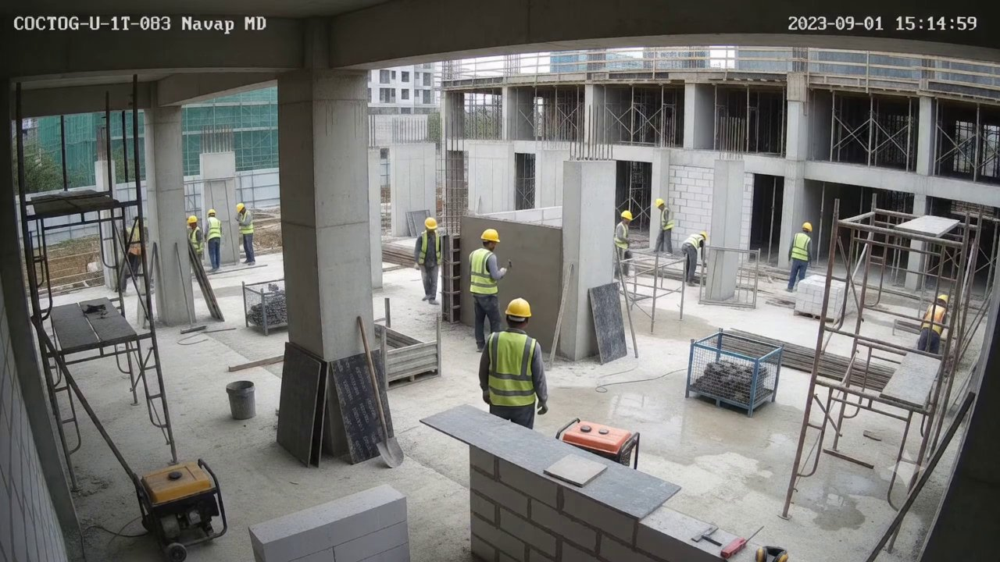


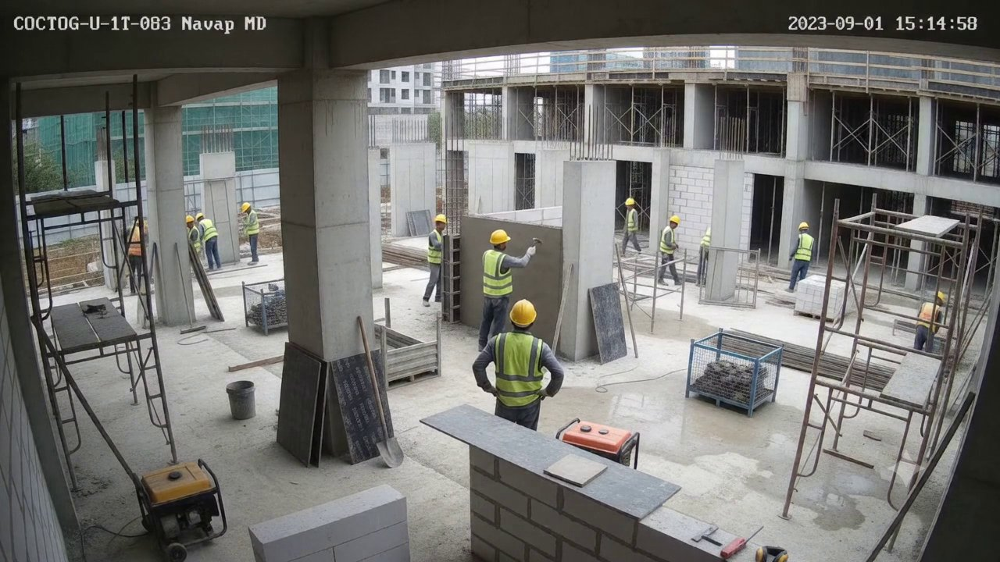


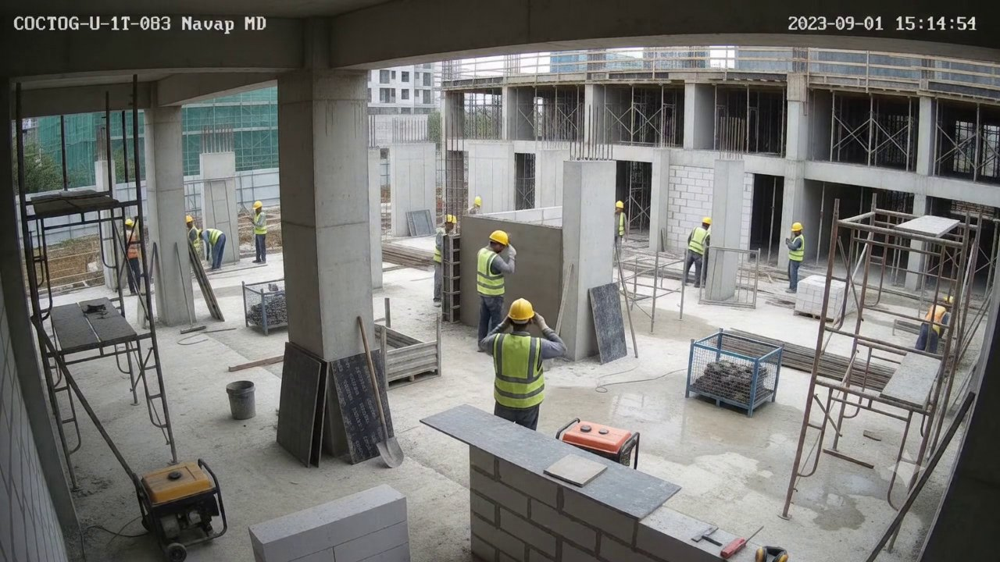


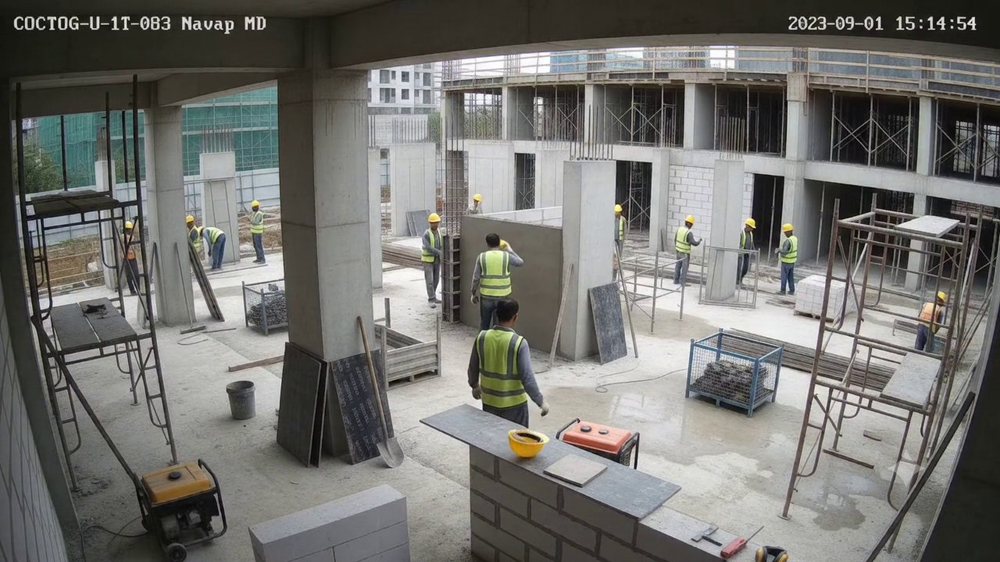


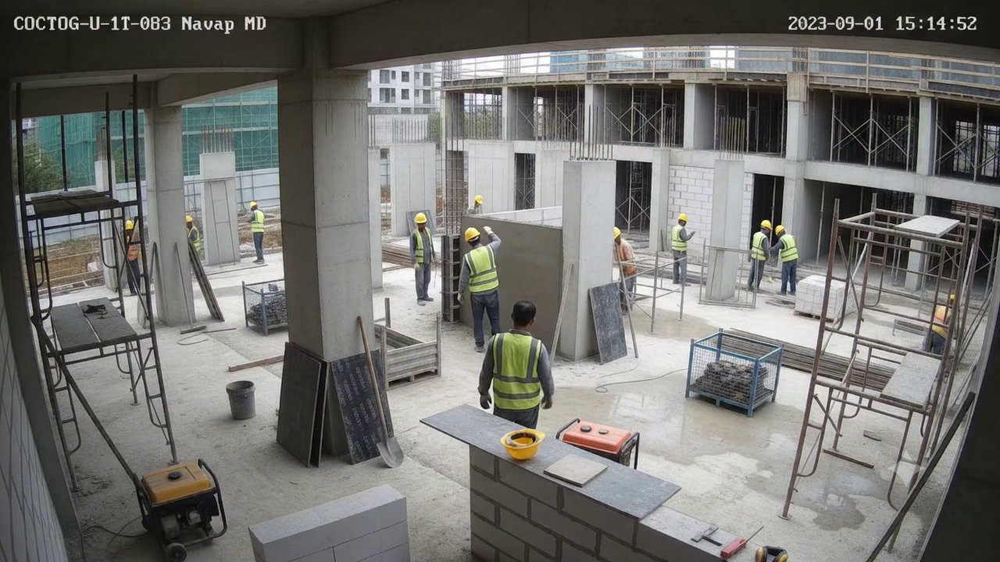

Descriptions saved to: /content/ppe_frame_descriptions.json


In [19]:

import cv2
import torch
import html
import io
import base64
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display, HTML, Markdown

# ==================== CONFIGURATION ====================
VIDEO_PATH = "/content/cctv_worker_remove_hat.mp4"
FRAME_INTERVAL = 2       # Analyze one frame every 2 seconds
MAX_NEW_TOKENS = 300

# Uses the existing fine-tuned model and processor in this notebook.
assert "model" in globals(), "Fine-tuned model is not loaded."
assert "processor" in globals(), "Processor is not loaded."

# ==================== REASONING PROMPT ====================


PROMPT = """
Inspect this construction-site CCTV image objectively.

For each visible worker, examine the actual pixels around their head
and torso independently.

For every worker, report:
1. Approximate location in the image.
2. HEAD OBSERVATION: Describe what is visibly present on the head
   (for example, yellow hard hat, uncovered head, or not clear).
3. HELMET STATUS: WORN, MISSING, or UNCERTAIN.
4. TORSO OBSERVATION: Describe the visible clothing and whether
   reflective strips or a high-visibility vest can be seen.
5. VEST STATUS: WORN, MISSING, or UNCERTAIN.
6. Evidence: Explain the visible details supporting the conclusion.

Rules:
- A helmet is WORN only if it is visibly on the worker's head.
- A helmet on a wall, in a hand, or nearby is not being worn.
- A vest is WORN only if it is visibly worn on the torso.
- Do not copy one worker's assessment to another worker.
- Do not label PPE as WORN without visual evidence.
- Do not label PPE as MISSING when the relevant body part is obscured.
- Use UNCERTAIN when the image does not allow a reliable judgment.
- Do not assume all workers have the same PPE status.
- Do not invent workers or visual details.
- Analyze this frame only; do not refer to previous frames.

OVERALL STATUS:
Choose COMPLIANT, VIOLATION, MIXED, or UNCERTAIN based on
the individual observations.

CONFIRMED VIOLATIONS:
List only violations supported by visible evidence.

UNCERTAINTIES:
List workers whose PPE cannot be judged reliably.

RECOMMENDED ACTION:
Give an appropriate action based on the evidence.

Do not assume compliance. Do not assume violations.
Do not repeat identical observations without worker-specific evidence.
"""



# ==================== MODEL INFERENCE ====================
def analyze_frame(image):
    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": PROMPT},
        ],
    }]

    chat_text = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )

    inputs = processor(
        text=[chat_text],
        images=[image],
        return_tensors="pt",
    ).to(model.device)

    with torch.inference_mode():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=MAX_NEW_TOKENS,
            do_sample=False,
        )

    generated_ids = output_ids[:, inputs.input_ids.shape[1]:]
    return processor.batch_decode(
        generated_ids,
        skip_special_tokens=True,
    )[0].strip()


# ==================== VIDEO PROCESSING ====================
cap = cv2.VideoCapture(VIDEO_PATH)

if not cap.isOpened():
    raise RuntimeError(f"Could not open video: {VIDEO_PATH}")

fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

if not fps or fps <= 0:
    cap.release()
    raise RuntimeError("Could not determine the video's FPS.")

duration = total_frames / fps
timestamps = list(range(0, int(duration) + 1, FRAME_INTERVAL))
results = []

try:
    for seconds in tqdm(timestamps, desc="Analyzing video"):
        cap.set(cv2.CAP_PROP_POS_MSEC, seconds * 1000)
        ok, frame = cap.read()

        if not ok:
            continue

        image = Image.fromarray(
            cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        )

        description = analyze_frame(image)

        results.append({
            "timestamp": f"{seconds // 60:02d}:{seconds % 60:02d}",
            "seconds": seconds,
            "image": image.copy(),
            "description": description,
        })
finally:
    cap.release()


# ==================== DISPLAY FRAME + REASONING ====================
print(f"Analysis complete: {len(results)} frames.")

for item in results:
    buffer = io.BytesIO()
    item["image"].save(buffer, format="JPEG", quality=85)
    encoded = base64.b64encode(buffer.getvalue()).decode("ascii")

    description_html = html.escape(item["description"])
    description_html = description_html.replace("\n", "<br>")

    display(HTML(f"""
    <div style="margin:20px 0;padding:16px;
                border:1px solid #666;border-radius:10px;">
      <h3 style="margin-top:0;">Timestamp: {item['timestamp']}</h3>
      <div style="display:flex;gap:18px;align-items:flex-start;
                  flex-wrap:wrap;">
        <div style="flex:1;min-width:280px;">
          <img src="data:image/jpeg;base64,{encoded}"
               style="width:100%;height:auto;border-radius:8px;">
        </div>
        <div style="flex:1;min-width:280px;line-height:1.65;
                    overflow-wrap:anywhere;">
          {description_html}
        </div>
      </div>
    </div>
    """))

# ==================== SAVE RESULTS ====================
import json

json_path = "/content/ppe_frame_descriptions.json"

with open(json_path, "w", encoding="utf-8") as f:
    json.dump(
        [
            {
                "timestamp": item["timestamp"],
                "description": item["description"],
            }
            for item in results
        ],
        f,
        indent=2,
        ensure_ascii=False,
    )

print(f"Descriptions saved to: {json_path}")


Analyzing video frames:   0%|          | 0/6 [00:00<?, ?it/s]

Analysis complete: 5 frames.



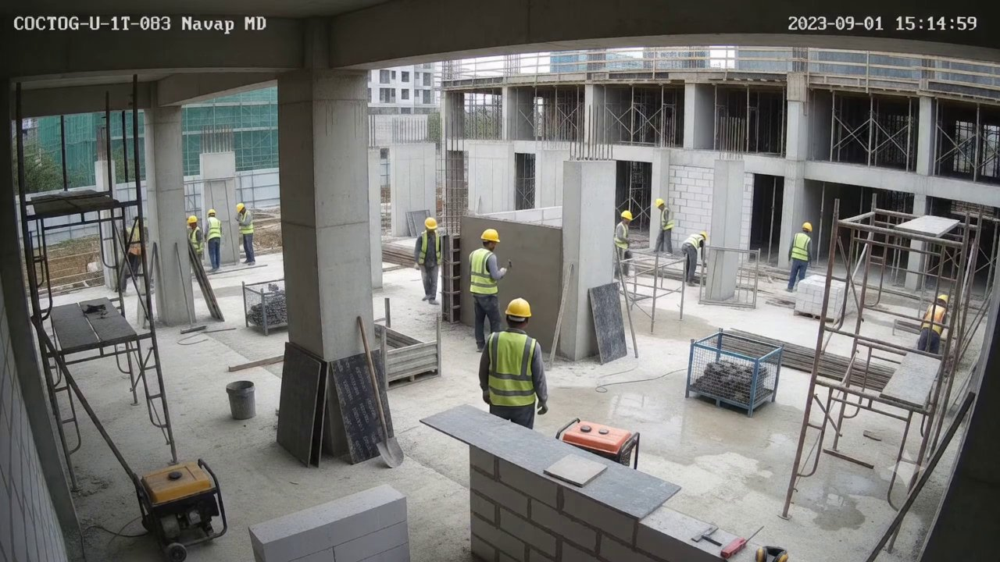


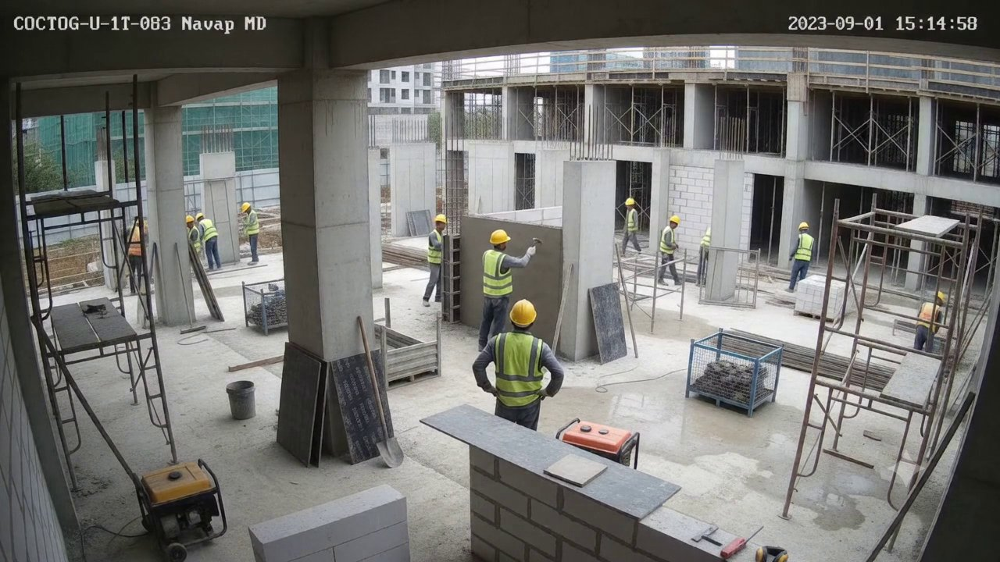


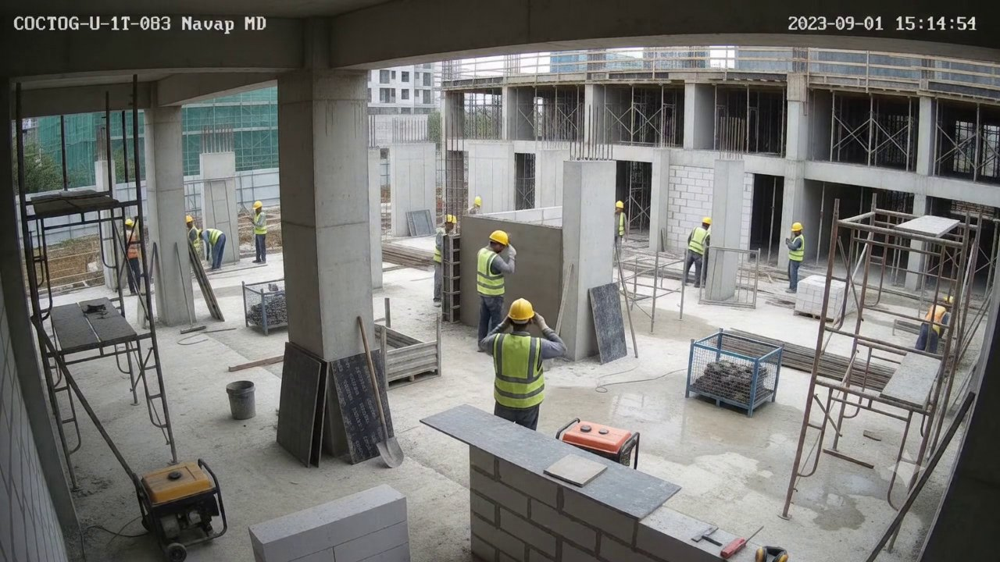


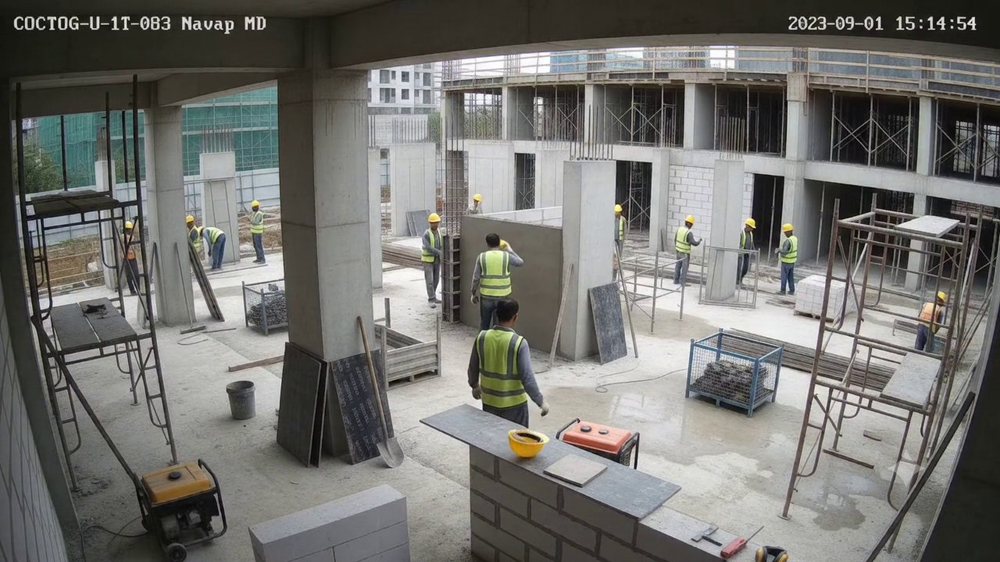


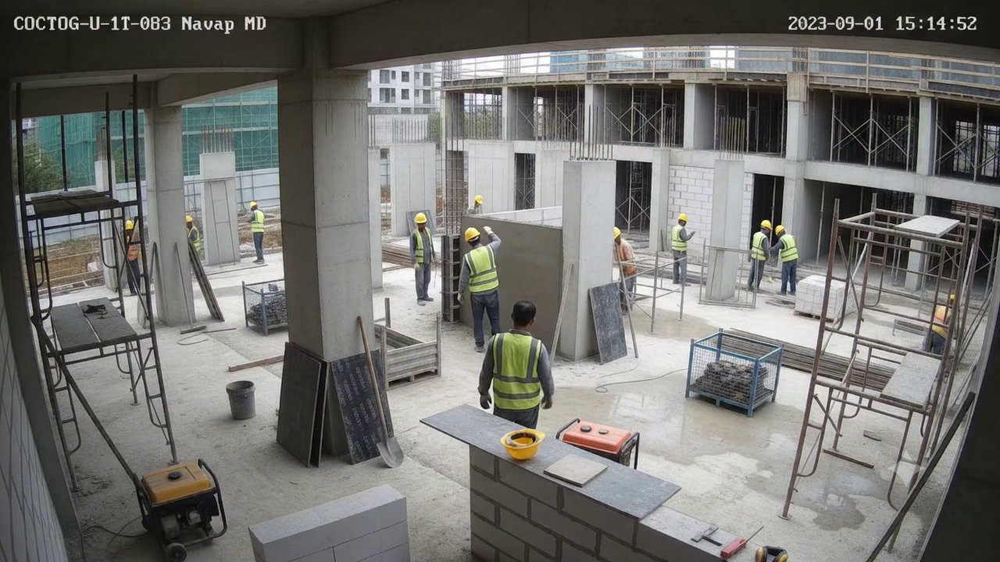

Descriptions saved to: /content/ppe_frame_descriptions.json


In [20]:

import cv2
import torch
import html
import io
import base64
import json
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display, HTML

# ================= CONFIGURATION =================
VIDEO_PATH = "/content/cctv_worker_remove_hat.mp4"
FRAME_INTERVAL = 2
MAX_NEW_TOKENS = 220

# ================= NEUTRAL PROMPT =================
PROMPT = """
Describe this construction-site CCTV frame objectively.

Describe the visible scene and construction activities.
Discuss PPE only to the extent supported by visible evidence.

If a worker's helmet or reflective vest is clearly visible, describe it.
If a worker's head or torso is visible without the relevant PPE, describe
that observation.
If the relevant area is too small, obscured, or ambiguous, say that
the PPE status cannot be determined.

Do not assume that all workers are compliant.
Do not assume that all workers are violating safety rules.
Do not assign the same PPE status to every worker without evidence.
Do not invent workers, objects, or actions.
Do not claim to compare with previous frames.

Return:
SCENE DESCRIPTION:
A concise description of the visible activity.

VISIBLE PPE EVIDENCE:
Describe clearly visible helmets, reflective vests, and any apparent
absence of PPE. Distinguish direct observations from uncertainty.

SAFETY ASSESSMENT:
State COMPLIANT, VIOLATION, MIXED, or UNCERTAIN only when supported
by the visual evidence. Explain briefly.

RECOMMENDED ACTION:
Suggest an appropriate action based on the evidence.
"""

# ================= FRAME INFERENCE =================
def analyze_frame(image):
    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": PROMPT},
        ],
    }]

    chat_text = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )

    inputs = processor(
        text=[chat_text],
        images=[image],
        return_tensors="pt",
    ).to(model.device)

    with torch.inference_mode():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=MAX_NEW_TOKENS,
            do_sample=False,
        )

    generated_ids = output_ids[:, inputs.input_ids.shape[1]:]

    return processor.batch_decode(
        generated_ids,
        skip_special_tokens=True,
    )[0].strip()


# ================= PROCESS VIDEO =================
cap = cv2.VideoCapture(VIDEO_PATH)

if not cap.isOpened():
    raise RuntimeError(f"Cannot open video: {VIDEO_PATH}")

fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

if not fps or fps <= 0:
    cap.release()
    raise RuntimeError("Cannot determine video FPS.")

duration = total_frames / fps
timestamps = list(range(0, int(duration) + 1, FRAME_INTERVAL))
results = []

try:
    for seconds in tqdm(timestamps, desc="Analyzing video frames"):
        cap.set(cv2.CAP_PROP_POS_MSEC, seconds * 1000)
        ok, frame = cap.read()

        if not ok:
            continue

        image = Image.fromarray(
            cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        )

        description = analyze_frame(image)

        results.append({
            "timestamp": f"{seconds // 60:02d}:{seconds % 60:02d}",
            "seconds": seconds,
            "image": image.copy(),
            "description": description,
        })
finally:
    cap.release()


# ================= DISPLAY FRAME + DESCRIPTION =================
print(f"Analysis complete: {len(results)} frames.")

for item in results:
    buffer = io.BytesIO()
    item["image"].save(buffer, format="JPEG", quality=85)
    encoded = base64.b64encode(buffer.getvalue()).decode("ascii")

    description_html = html.escape(item["description"])
    description_html = description_html.replace("\n", "<br>")

    display(HTML(f"""
    <div style="margin:20px 0;padding:16px;
                border:1px solid #666;border-radius:10px;">
      <h3 style="margin-top:0;">Timestamp: {item['timestamp']}</h3>
      <div style="display:flex;gap:18px;align-items:flex-start;
                  flex-wrap:wrap;">
        <div style="flex:1;min-width:280px;">
          <img src="data:image/jpeg;base64,{encoded}"
               style="width:100%;height:auto;border-radius:8px;">
        </div>
        <div style="flex:1;min-width:280px;line-height:1.65;
                    overflow-wrap:anywhere;">
          {description_html}
        </div>
      </div>
    </div>
    """))


# ================= SAVE DESCRIPTIONS =================
OUTPUT_JSON = "/content/ppe_frame_descriptions.json"

with open(OUTPUT_JSON, "w", encoding="utf-8") as f:
    json.dump(
        [
            {
                "timestamp": item["timestamp"],
                "description": item["description"],
            }
            for item in results
        ],
        f,
        indent=2,
        ensure_ascii=False,
    )

print(f"Descriptions saved to: {OUTPUT_JSON}")


Analyzing video with context:   0%|          | 0/6 [00:00<?, ?it/s]

Analysis complete: 5 frames.



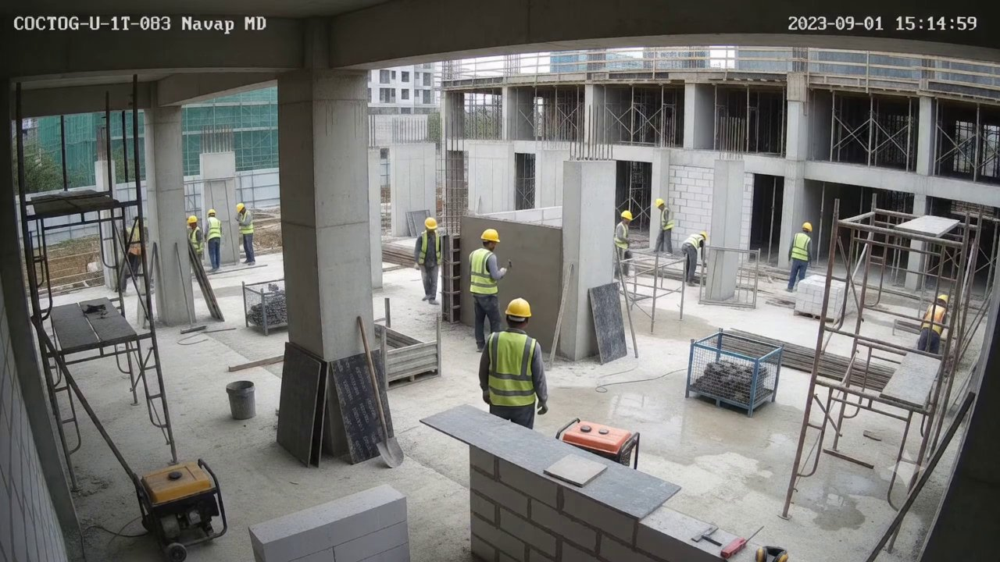


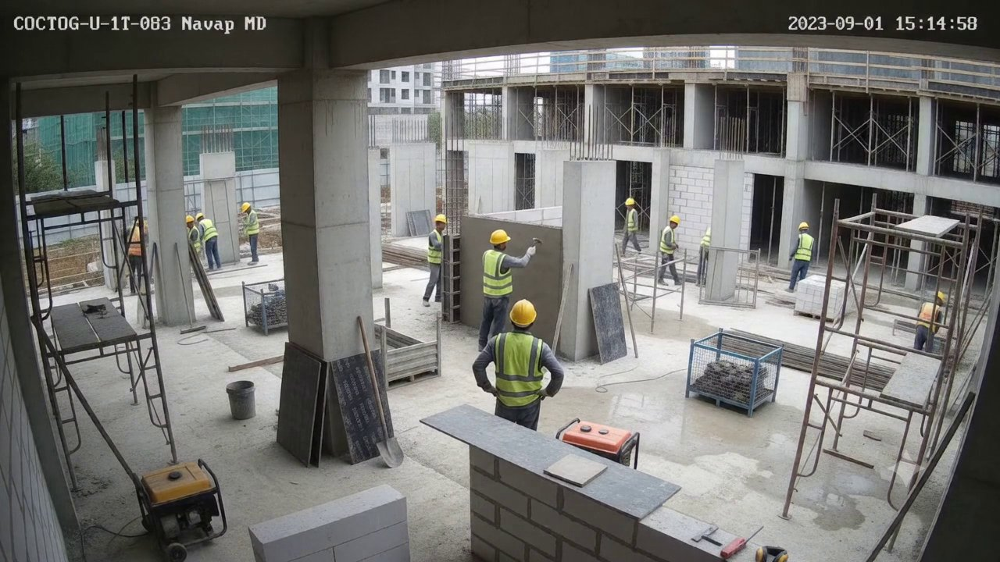


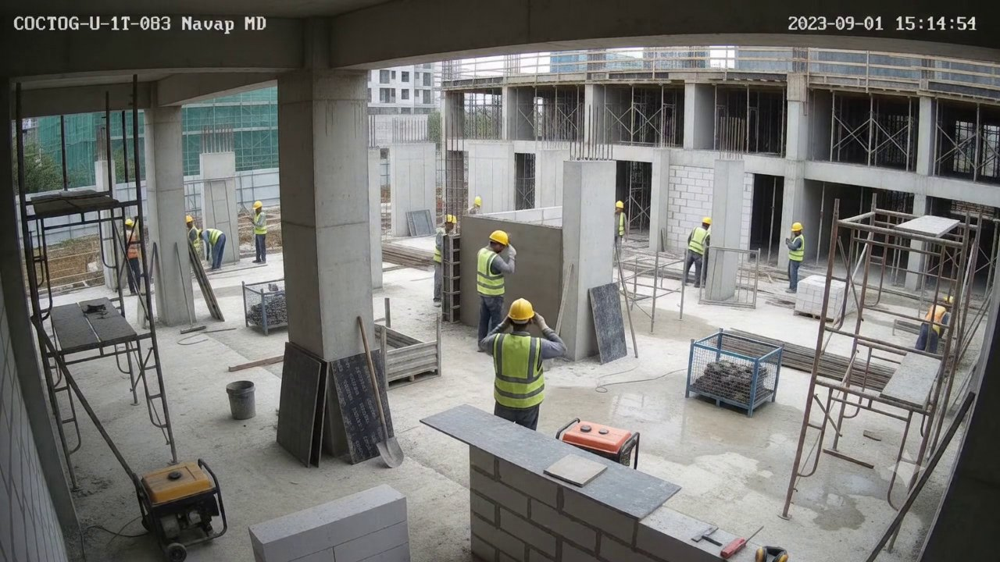


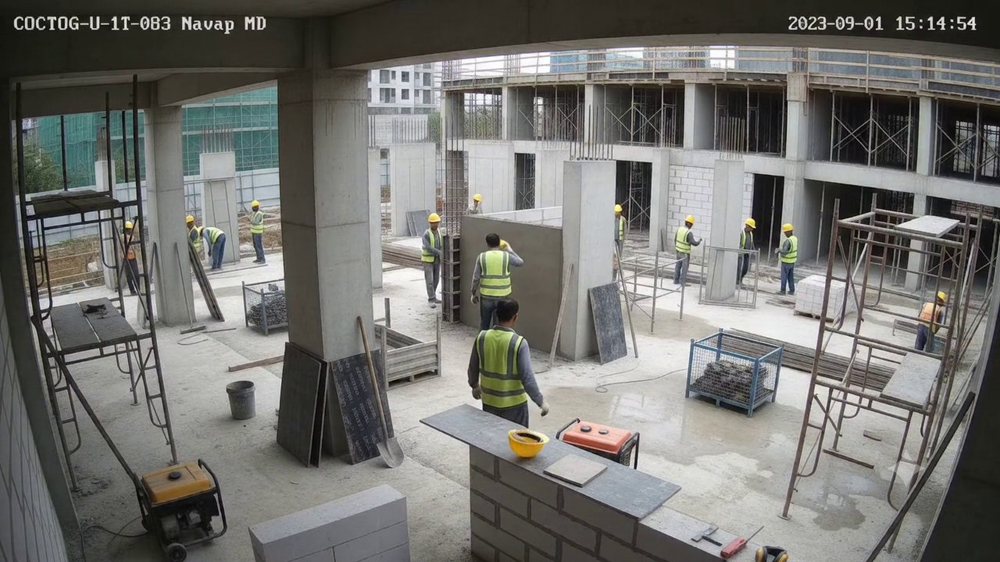


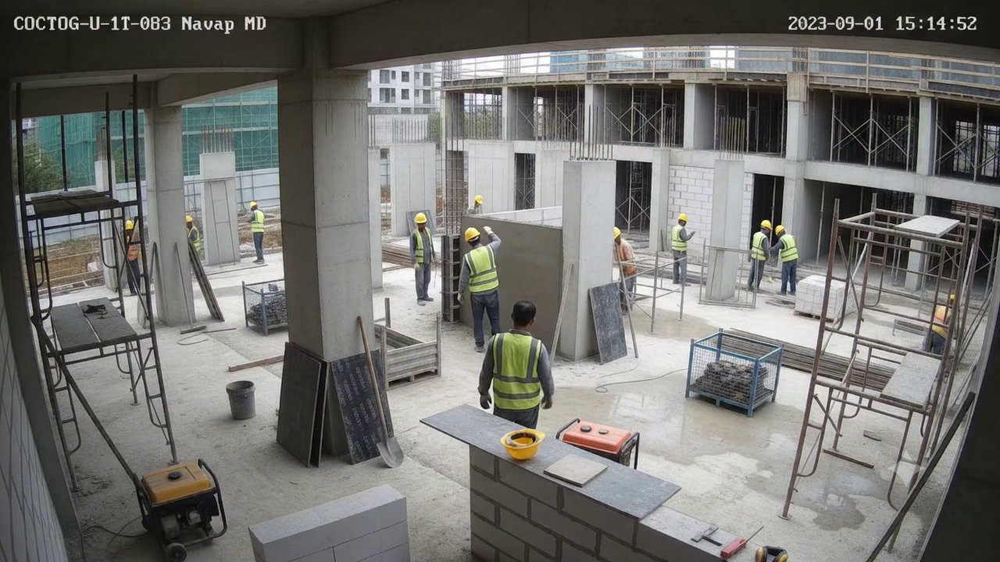

Saved descriptions to /content/ppe_frame_descriptions_temporal.json


In [21]:

import cv2, torch, html, io, base64, json
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display, HTML

# ================= CONFIGURATION =================
VIDEO_PATH = "/content/cctv_worker_remove_hat.mp4"
FRAME_INTERVAL = 2       # Analyze one frame every 2 seconds
MAX_NEW_TOKENS = 300
HISTORY_FRAMES = 3       # Include the previous 3 frame descriptions

assert "model" in globals(), "Your fine-tuned model is not loaded."
assert "processor" in globals(), "The processor is not loaded."

# ================= PROMPT =================
BASE_PROMPT = """
Analyze this construction-site CCTV frame for PPE safety.

Describe the visible scene and assess helmet and reflective-vest use
based on visual evidence.

For each distinguishable worker, describe their approximate location,
helmet status (WORN, MISSING, or UNCERTAIN), vest status
(WORN, MISSING, or UNCERTAIN), and the evidence supporting each status.

A helmet nearby or held in a hand is not being worn.
A vest counts as worn only when visibly worn on the torso.
Do not assume compliance or violations. Do not invent details.
If a body part is obscured or too small to assess, use UNCERTAIN.

Return:
SCENE DESCRIPTION:
WORKER OBSERVATIONS:
OVERALL ASSESSMENT: COMPLIANT / VIOLATION / MIXED / UNCERTAIN
CONFIRMED VIOLATIONS:
UNCERTAINTIES:
RECOMMENDED ACTION:

Report only what the image supports. Do not claim all workers have
the same PPE status without individual evidence.
"""

# ================= FRAME INFERENCE WITH HISTORY =================
def analyze_frame(image, previous_context):
    prompt = f"""
{BASE_PROMPT}

PREVIOUS FRAME CONTEXT:
{previous_context}

TEMPORAL INSTRUCTIONS:
Use previous descriptions as context to maintain continuity in the
scene. Analyze the current image directly and prioritize what is
visible now. PPE status can change between frames. Do not copy an
earlier assessment without checking the current image. Do not assume
workers are the same person unless visual continuity supports it.
Explain any clearly supported change. If no change can be established,
say so. Previous descriptions may contain errors, so verify them
against the current image.
"""

    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": prompt},
        ],
    }]

    chat_text = processor.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )
    inputs = processor(
        text=[chat_text],
        images=[image],
        return_tensors="pt",
    ).to(model.device)

    with torch.inference_mode():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=MAX_NEW_TOKENS,
            do_sample=False,
        )

    new_tokens = output_ids[:, inputs.input_ids.shape[1]:]
    return processor.batch_decode(
        new_tokens, skip_special_tokens=True
    )[0].strip()


# ================= PROCESS VIDEO SEQUENTIALLY =================
cap = cv2.VideoCapture(VIDEO_PATH)
if not cap.isOpened():
    raise RuntimeError(f"Cannot open video: {VIDEO_PATH}")

fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
if not fps or fps <= 0:
    cap.release()
    raise RuntimeError("Cannot determine video FPS.")

duration = total_frames / fps
timestamps = list(range(0, int(duration) + 1, FRAME_INTERVAL))
results = []
history = []

try:
    for seconds in tqdm(timestamps, desc="Analyzing video with context"):
        cap.set(cv2.CAP_PROP_POS_MSEC, seconds * 1000)
        ok, frame = cap.read()
        if not ok:
            continue

        image = Image.fromarray(
            cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        )

        previous_context = (
            "\n\n".join(history[-HISTORY_FRAMES:])
            if history else "No previous frame observations."
        )

        description = analyze_frame(image, previous_context)
        timestamp = f"{seconds // 60:02d}:{seconds % 60:02d}"

        results.append({
            "timestamp": timestamp,
            "seconds": seconds,
            "image": image.copy(),
            "description": description,
        })

        # Only text descriptions are passed forward as context.
        history.append(f"Timestamp {timestamp}:\n{description}")

finally:
    cap.release()

# ================= DISPLAY: FRAME + DESCRIPTION =================
print(f"Analysis complete: {len(results)} frames.")

for item in results:
    buffer = io.BytesIO()
    item["image"].save(buffer, format="JPEG", quality=85)
    encoded = base64.b64encode(buffer.getvalue()).decode("ascii")
    description_html = html.escape(item["description"]).replace("\n", "<br>")

    display(HTML(f"""
    <div style="margin:20px 0;padding:16px;
                border:1px solid #666;border-radius:10px;">
      <h3 style="margin-top:0;">Timestamp: {item['timestamp']}</h3>
      <div style="display:flex;gap:18px;align-items:flex-start;
                  flex-wrap:wrap;">
        <div style="flex:1;min-width:280px;">
          <img src="data:image/jpeg;base64,{encoded}"
               style="width:100%;height:auto;border-radius:8px;">
        </div>
        <div style="flex:1;min-width:280px;line-height:1.65;
                    overflow-wrap:anywhere;">
          {description_html}
        </div>
      </div>
    </div>
    """))

# ================= SAVE RESULTS =================
OUTPUT_JSON = "/content/ppe_frame_descriptions_temporal.json"
with open(OUTPUT_JSON, "w", encoding="utf-8") as f:
    json.dump(
        [
            {"timestamp": r["timestamp"], "description": r["description"]}
            for r in results
        ],
        f, indent=2, ensure_ascii=False
    )

print(f"Saved descriptions to {OUTPUT_JSON}")


Evaluating PPE predictions:   0%|          | 0/6 [00:00<?, ?it/s]


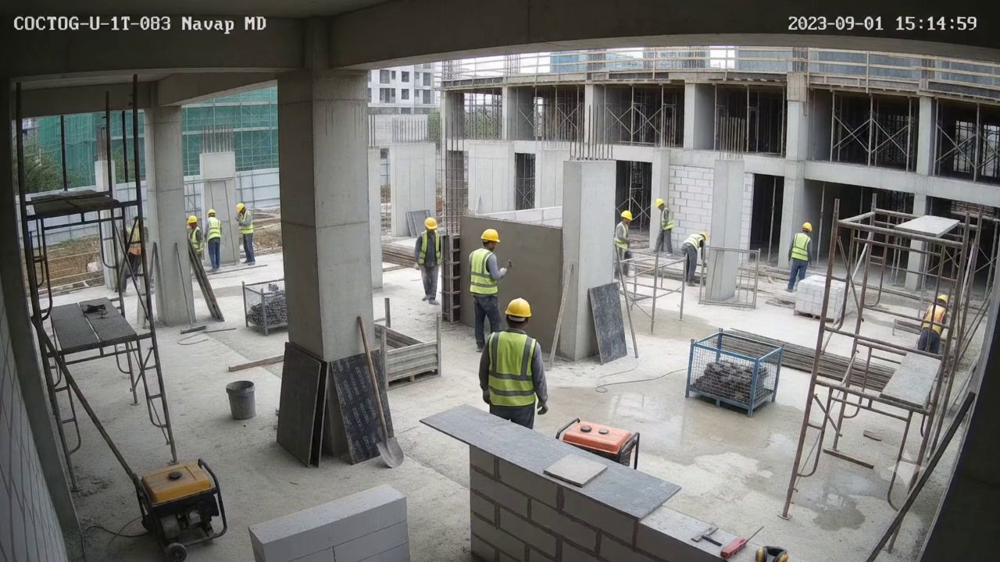


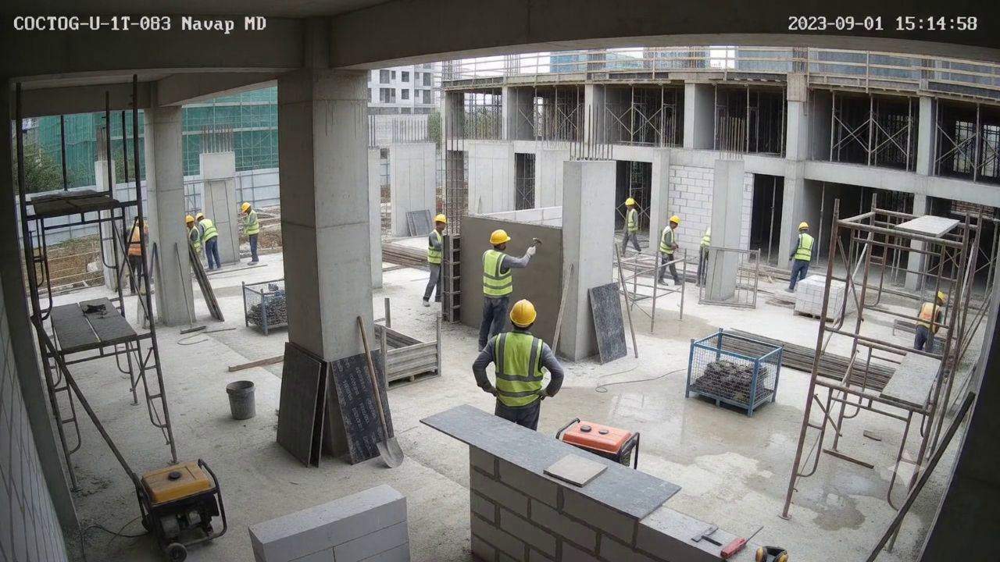


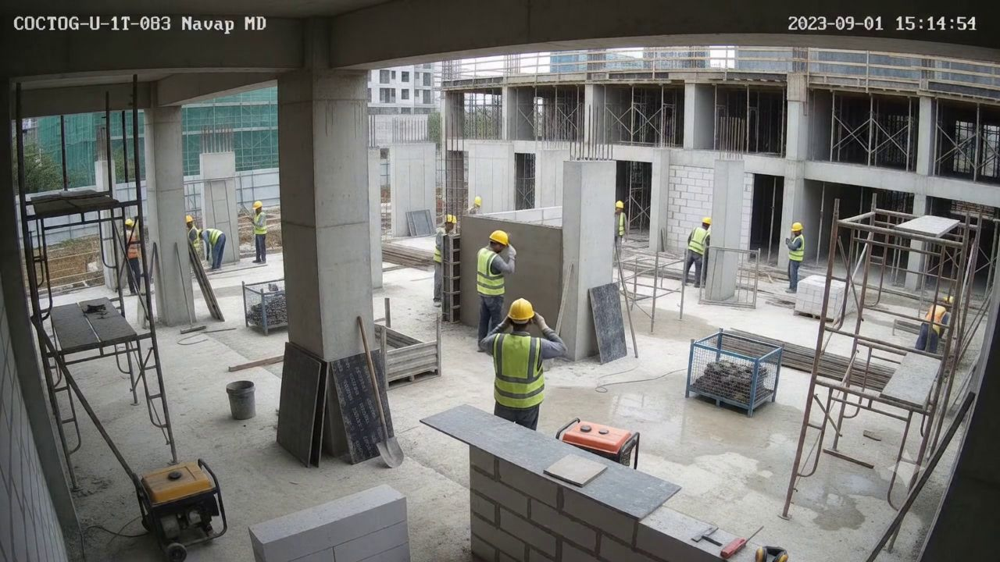


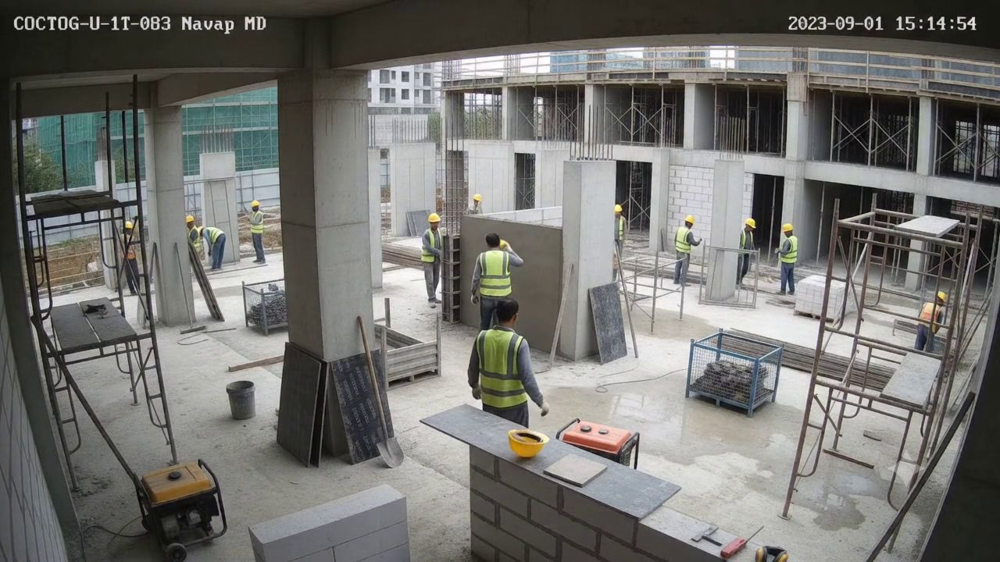


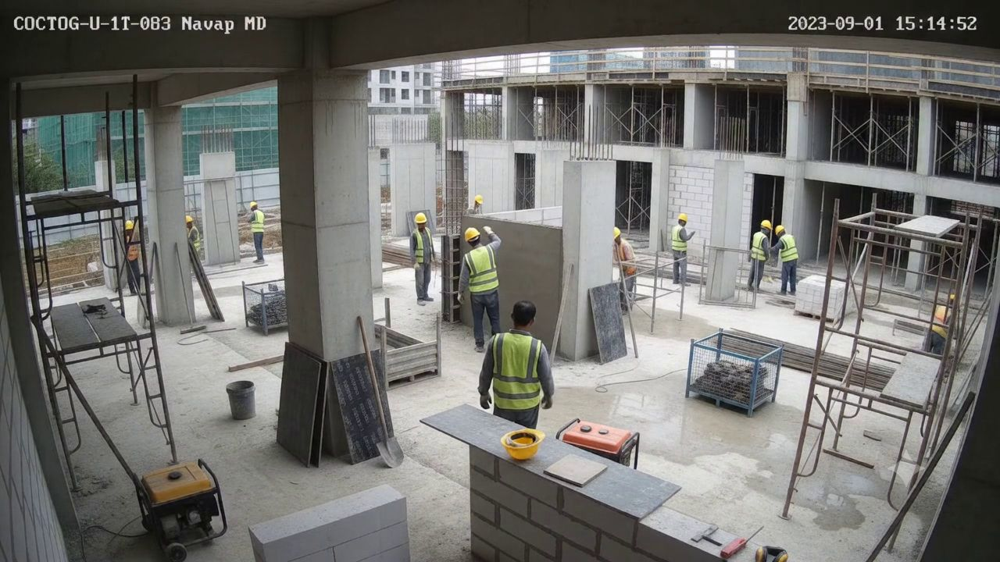


EVALUATION INFERENCE COMPLETE
Sampled frames: 5
Prediction rows: 5
Annotation CSV: /content/ppe_evaluation_annotations.csv
Raw predictions: /content/ppe_evaluation_raw_predictions.json

No accuracy score is claimed yet: ground-truth labels are blank.
Fill gt_helmet and gt_vest with manually verified labels:
WORN, MISSING, or UNCERTAIN.


In [22]:

# ============================================================
# HONEST PPE MODEL EVALUATION — ONE COLAB CELL
# Uses the existing fine-tuned model. No training.
# ============================================================

import cv2
import torch
import json
import re
import pandas as pd
import html
import base64
import io
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display, HTML
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

VIDEO_PATH = "/content/cctv_worker_remove_hat.mp4"
INTERVAL_SECONDS = 2
MAX_NEW_TOKENS = 350

assert "model" in globals(), "Fine-tuned model is not loaded."
assert "processor" in globals(), "Processor is not loaded."

# Keep uncertain cases distinct from positive/negative labels.
PROMPT = """
You are evaluating PPE compliance in a construction-site CCTV image.

Inspect the CURRENT IMAGE only. Do not assume compliance.
For every distinguishable worker, assess:

helmet_status: WORN, MISSING, or UNCERTAIN
vest_status: WORN, MISSING, or UNCERTAIN

Rules:
- WORN means the item is visibly being worn correctly.
- MISSING means the relevant area is visible enough to establish
  that the item is not being worn.
- UNCERTAIN means the worker is too small, obscured, or ambiguous.
- A helmet carried in a hand does not count as WORN.
- Do not invent workers or infer invisible details.
- Do not claim certainty when visual evidence is insufficient.
- Give each worker an approximate image location.
- Report only evidence visible in this image.

Return ONLY valid JSON in this exact structure:
{
  "scene_summary": "brief factual description",
  "workers": [
    {
      "worker_id": "W1",
      "location": "approximate image location",
      "helmet_status": "WORN or MISSING or UNCERTAIN",
      "helmet_evidence": "visible evidence",
      "vest_status": "WORN or MISSING or UNCERTAIN",
      "vest_evidence": "visible evidence"
    }
  ],
  "limitations": "visibility limitations or none"
}

If no worker can be reliably identified, return an empty workers list.
"""

def predict_frame(image):
    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": PROMPT}
        ]
    }]

    chat_text = processor.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )
    inputs = processor(
        text=[chat_text], images=[image], return_tensors="pt"
    ).to(model.device)

    with torch.inference_mode():
        output = model.generate(
            **inputs,
            max_new_tokens=MAX_NEW_TOKENS,
            do_sample=False
        )

    generated = output[:, inputs.input_ids.shape[1]:]
    text_out = processor.batch_decode(
        generated, skip_special_tokens=True
    )[0].strip()

    # Extract JSON even if the model adds surrounding text.
    try:
        match = re.search(r"\{.*\}", text_out, re.DOTALL)
        if not match:
            raise ValueError("No JSON object found")
        parsed = json.loads(match.group())
        if not isinstance(parsed.get("workers"), list):
            raise ValueError("Missing workers list")
        return parsed, text_out, None
    except Exception as e:
        return None, text_out, str(e)

cap = cv2.VideoCapture(VIDEO_PATH)
if not cap.isOpened():
    raise RuntimeError(f"Cannot open video: {VIDEO_PATH}")

fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

if not fps or fps <= 0 or frame_count <= 0:
    cap.release()
    raise RuntimeError("Could not read video FPS/frame count.")

duration = frame_count / fps
sample_times = list(range(0, int(duration) + 1, INTERVAL_SECONDS))

records = []
frame_cache = []

try:
    for sec in tqdm(sample_times, desc="Evaluating PPE predictions"):
        cap.set(cv2.CAP_PROP_POS_MSEC, sec * 1000)
        ok, frame = cap.read()
        if not ok:
            continue

        image = Image.fromarray(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        result, raw_output, error = predict_frame(image)

        timestamp = f"{sec // 60:02d}:{sec % 60:02d}"
        frame_id = f"frame_{sec:06d}"

        if result is None:
            records.append({
                "frame_id": frame_id,
                "timestamp": timestamp,
                "worker_id": "PARSE_ERROR",
                "location": "",
                "pred_helmet": "INVALID",
                "pred_helmet_evidence": "",
                "pred_vest": "INVALID",
                "pred_vest_evidence": "",
                "scene_summary": "",
                "limitations": "",
                "raw_output": raw_output,
                "parse_error": error,
                "gt_helmet": "",
                "gt_vest": ""
            })
        elif not result["workers"]:
            # Preserve empty detections; do not silently drop them.
            records.append({
                "frame_id": frame_id,
                "timestamp": timestamp,
                "worker_id": "NO_WORKERS_RETURNED",
                "location": "",
                "pred_helmet": "INVALID",
                "pred_helmet_evidence": "",
                "pred_vest": "INVALID",
                "pred_vest_evidence": "",
                "scene_summary": result.get("scene_summary", ""),
                "limitations": result.get("limitations", ""),
                "raw_output": raw_output,
                "parse_error": "",
                "gt_helmet": "",
                "gt_vest": ""
            })
        else:
            for idx, worker in enumerate(result["workers"], 1):
                helmet = str(worker.get("helmet_status", "INVALID")).upper()
                vest = str(worker.get("vest_status", "INVALID")).upper()

                if helmet not in {"WORN", "MISSING", "UNCERTAIN"}:
                    helmet = "INVALID"
                if vest not in {"WORN", "MISSING", "UNCERTAIN"}:
                    vest = "INVALID"

                records.append({
                    "frame_id": frame_id,
                    "timestamp": timestamp,
                    "worker_id": worker.get("worker_id", f"W{idx}"),
                    "location": worker.get("location", ""),
                    "pred_helmet": helmet,
                    "pred_helmet_evidence": worker.get("helmet_evidence", ""),
                    "pred_vest": vest,
                    "pred_vest_evidence": worker.get("vest_evidence", ""),
                    "scene_summary": result.get("scene_summary", ""),
                    "limitations": result.get("limitations", ""),
                    "raw_output": raw_output,
                    "parse_error": "",
                    "gt_helmet": "",
                    "gt_vest": ""
                })

        # Keep the frame for side-by-side inspection.
        frame_cache.append((timestamp, image.copy(), raw_output))

finally:
    cap.release()

df = pd.DataFrame(records)

# Save all raw predictions and annotation template.
CSV_PATH = "/content/ppe_evaluation_annotations.csv"
JSON_PATH = "/content/ppe_evaluation_raw_predictions.json"

df.to_csv(CSV_PATH, index=False, encoding="utf-8-sig")
with open(JSON_PATH, "w", encoding="utf-8") as f:
    json.dump(records, f, indent=2, ensure_ascii=False)

# Display each sampled frame beside the model output.
for timestamp, image, raw_output in frame_cache:
    buf = io.BytesIO()
    image.save(buf, format="JPEG", quality=80)
    encoded = base64.b64encode(buf.getvalue()).decode()

    display(HTML(f"""
    <div style="border:1px solid #888;border-radius:8px;
                padding:12px;margin:14px 0;">
      <h3>Timestamp: {html.escape(timestamp)}</h3>
      <div style="display:flex;gap:16px;flex-wrap:wrap;
                  align-items:flex-start;">
        <div style="flex:1;min-width:280px;">
          <img src="data:image/jpeg;base64,{encoded}"
               style="width:100%;height:auto;border-radius:6px;">
        </div>
        <pre style="flex:1;min-width:280px;white-space:pre-wrap;
                    overflow-wrap:anywhere;">{html.escape(raw_output)}</pre>
      </div>
    </div>
    """))

print("\nEVALUATION INFERENCE COMPLETE")
print("Sampled frames:", len(frame_cache))
print("Prediction rows:", len(df))
print("Annotation CSV:", CSV_PATH)
print("Raw predictions:", JSON_PATH)
print("\nNo accuracy score is claimed yet: ground-truth labels are blank.")
print("Fill gt_helmet and gt_vest with manually verified labels:")
print("WORN, MISSING, or UNCERTAIN.")


In [23]:

import pandas as pd
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from IPython.display import display

# Uploaded corrected CSV
CSV_PATH = "/content/ppe_evaluation_annotations.csv"

df = pd.read_csv(CSV_PATH).fillna("")

LABELS = ["WORN", "MISSING", "UNCERTAIN"]

print("=" * 65)
print("FINE-TUNED QWEN PPE MODEL — EVALUATION RESULTS")
print("=" * 65)
print("CSV rows:", len(df))

for item in ["helmet", "vest"]:
    pred_col = f"pred_{item}"
    gt_col = f"gt_{item}"

    required = [pred_col, gt_col]
    missing_cols = [c for c in required if c not in df.columns]
    if missing_cols:
        raise ValueError(
            f"Missing columns {missing_cols}. "
            f"CSV columns found: {list(df.columns)}"
        )

    pred = df[pred_col].astype(str).str.strip().str.upper()
    gt = df[gt_col].astype(str).str.strip().str.upper()

    # Only rows with valid, manually verified ground truth.
    mask = gt.isin(LABELS)
    y_true = gt[mask]
    y_pred = pred[mask].where(pred[mask].isin(LABELS), "__INVALID__")

    print("\n" + "=" * 65)
    print(f"{item.upper()} METRICS")
    print("=" * 65)
    print("Rows with valid ground truth:", len(y_true))
    print("Rows without valid ground truth:", len(df) - len(y_true))

    if len(y_true) == 0:
        print("No valid ground-truth labels found. Check the CSV.")
        continue

    # Invalid model predictions count as incorrect.
    accuracy = accuracy_score(y_true, y_pred)
    print(f"\nStrict accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
    print(f"Invalid prediction rate: {(y_pred == '__INVALID__').mean() * 100:.2f}%")

    print("\nClassification report:")
    print(classification_report(
        y_true,
        y_pred,
        labels=LABELS + ["__INVALID__"],
        target_names=LABELS + ["INVALID"],
        digits=4,
        zero_division=0
    ))

    print("Confusion matrix")
    print("Rows = ground truth; columns = model prediction")
    print("Order:", LABELS + ["INVALID"])
    print(confusion_matrix(
        y_true,
        y_pred,
        labels=LABELS + ["__INVALID__"]
    ))

    # Binary violation detection:
    # MISSING = violation; WORN = compliant.
    # UNCERTAIN cases are excluded from this binary metric.
    binary_mask = (
        y_true.isin(["WORN", "MISSING"])
        & y_pred.isin(["WORN", "MISSING"])
    )

    yt = (y_true[binary_mask] == "MISSING").astype(int)
    yp = (y_pred[binary_mask] == "MISSING").astype(int)

    print("\nPPE violation detection (MISSING = positive class)")
    print("Definite WORN/MISSING prediction-ground-truth pairs:", len(yt))

    if len(yt):
        print(f"Violation precision: {precision_score(yt, yp, zero_division=0):.4f}")
        print(f"Violation recall:    {recall_score(yt, yp, zero_division=0):.4f}")
        print(f"Violation F1-score:  {f1_score(yt, yp, zero_division=0):.4f}")
    else:
        print("No definite pairs available for binary metrics.")

    # Save row-by-row comparison for error inspection.
    comparison = df.loc[mask, [
        c for c in ["frame_id", "timestamp", "worker_id", "location"]
        if c in df.columns
    ]].copy()
    comparison["ground_truth"] = y_true.values
    comparison["prediction"] = y_pred.values
    comparison["correct"] = (
        comparison["ground_truth"] == comparison["prediction"]
    )

    output_path = f"/content/{item}_evaluation_comparison.csv"
    comparison.to_csv(output_path, index=False)
    print("Row-by-row results saved to:", output_path)

print("\nEvaluation complete.")
print("Interpret metrics using the number of manually labelled rows.")


FINE-TUNED QWEN PPE MODEL — EVALUATION RESULTS
CSV rows: 5

HELMET METRICS
Rows with valid ground truth: 0
Rows without valid ground truth: 5
No valid ground-truth labels found. Check the CSV.

VEST METRICS
Rows with valid ground truth: 0
Rows without valid ground truth: 5
No valid ground-truth labels found. Check the CSV.

Evaluation complete.
Interpret metrics using the number of manually labelled rows.


In [24]:
import pandas as pd

path = "/content/ppe_evaluation_annotations.csv"
df = pd.read_csv(path)

print("Columns found:")
print(df.columns.tolist())

print("\nCSV contents:")
display(df)

for col in ["gt_helmet", "gt_vest"]:
    if col in df.columns:
        print(f"\nValues in {col}:")
        print(df[col].value_counts(dropna=False))

Columns found:
['frame_id', 'timestamp', 'worker_id', 'location', 'pred_helmet', 'pred_helmet_evidence', 'pred_vest', 'pred_vest_evidence', 'scene_summary', 'limitations', 'raw_output', 'parse_error', 'gt_helmet', 'gt_vest']

CSV contents:


,frame_id,timestamp,worker_id,location,pred_helmet,pred_helmet_evidence,pred_vest,pred_vest_evidence,scene_summary,limitations,raw_output,parse_error,gt_helmet,gt_vest
0,frame_000000,00:00,PARSE_ERROR,NaN,INVALID,NaN,INVALID,NaN,NaN,NaN,"```json\n{\n ""scene_summary"": ""A construction...","Expecting ',' delimiter: line 35 column 6 (cha...",NaN,NaN
1,frame_000002,00:02,PARSE_ERROR,NaN,INVALID,NaN,INVALID,NaN,NaN,NaN,"```json\n{\n ""scene_summary"": ""A construction...","Expecting ',' delimiter: line 27 column 6 (cha...",NaN,NaN
2,frame_000004,00:04,PARSE_ERROR,NaN,INVALID,NaN,INVALID,NaN,NaN,NaN,"```json\n{\n ""scene_summary"": ""A construction...","Expecting ',' delimiter: line 35 column 6 (cha...",NaN,NaN
3,frame_000006,00:06,PARSE_ERROR,NaN,INVALID,NaN,INVALID,NaN,NaN,NaN,"{\n ""scene_summary"": ""A construction site wit...","Expecting ',' delimiter: line 35 column 6 (cha...",NaN,NaN
4,frame_000008,00:08,PARSE_ERROR,NaN,INVALID,NaN,INVALID,NaN,NaN,NaN,"{\n ""scene_summary"": ""A construction site wit...","Expecting ',' delimiter: line 27 column 6 (cha...",NaN,NaN



Values in gt_helmet:
gt_helmet
NaN    5
Name: count, dtype: int64

Values in gt_vest:
gt_vest
NaN    5
Name: count, dtype: int64


In [25]:

import pandas as pd
import json
from IPython.display import display

csv_path = "/content/ppe_evaluation_annotations.csv"
json_path = "/content/ppe_evaluation_raw_predictions.json"

df = pd.read_csv(csv_path)

print("=== CSV ground-truth columns ===")
display(df[[
    c for c in [
        "frame_id", "timestamp", "worker_id",
        "pred_helmet", "pred_vest", "gt_helmet", "gt_vest",
        "parse_error"
    ] if c in df.columns
]])

print("\n=== Original raw model outputs ===")
with open(json_path, "r", encoding="utf-8") as f:
    raw_records = json.load(f)

for i, record in enumerate(raw_records, 1):
    print(f"\n--- Record {i}: {record.get('timestamp', 'unknown')} ---")
    print(record.get("raw_output", "No raw output found"))


=== CSV ground-truth columns ===


,frame_id,timestamp,worker_id,pred_helmet,pred_vest,gt_helmet,gt_vest,parse_error
0,frame_000000,00:00,PARSE_ERROR,INVALID,INVALID,NaN,NaN,"Expecting ',' delimiter: line 35 column 6 (cha..."
1,frame_000002,00:02,PARSE_ERROR,INVALID,INVALID,NaN,NaN,"Expecting ',' delimiter: line 27 column 6 (cha..."
2,frame_000004,00:04,PARSE_ERROR,INVALID,INVALID,NaN,NaN,"Expecting ',' delimiter: line 35 column 6 (cha..."
3,frame_000006,00:06,PARSE_ERROR,INVALID,INVALID,NaN,NaN,"Expecting ',' delimiter: line 35 column 6 (cha..."
4,frame_000008,00:08,PARSE_ERROR,INVALID,INVALID,NaN,NaN,"Expecting ',' delimiter: line 27 column 6 (cha..."



=== Original raw model outputs ===

--- Record 1: 00:00 ---
```json
{
  "scene_summary": "A construction site with multiple workers engaged in various tasks. The workers are wearing safety vests and hard hats.",
  "workers": [
    {
      "worker_id": "W1",
      "location": "Left side of the image, near the scaffolding",
      "helmet_status": "WORN",
      "helmet_evidence": "Visible on the head",
      "vest_status": "WORN",
      "vest_evidence": "Visible on the torso"
    },
    {
      "worker_id": "W2",
      "location": "Center-left of the image, near the concrete blocks",
      "helmet_status": "WORN",
      "helmet_evidence": "Visible on the head",
      "vest_status": "WORN",
      "vest_evidence": "Visible on the torso"
    },
    {
      "worker_id": "W3",
      "location": "Center-right of the image, near the scaffolding",
      "helmet_status": "WORN",
      "helmet_evidence": "Visible on the head",
      "vest_status": "WORN",
      "vest_evidence": "Visible on the tor

In [26]:

import cv2, torch, json, re, pandas as pd
from PIL import Image
from tqdm.auto import tqdm

VIDEO_PATH = "/content/cctv_worker_remove_hat.mp4"
OUTPUT_CSV = "/content/ppe_evaluation_annotations.csv"

PROMPT = """
Inspect this CCTV image for worker PPE compliance.
Return only one complete JSON object. No Markdown fences.

Schema:
{
 "scene_summary": "short description",
 "workers": [
  {
   "worker_id": "W1",
   "location": "approximate image location",
   "helmet_status": "WORN, MISSING, or UNCERTAIN",
   "vest_status": "WORN, MISSING, or UNCERTAIN"
  }
 ]
}

Only describe visible evidence. Do not assume all workers have
the same PPE status. Use UNCERTAIN if visibility is insufficient.
Include each visible worker you can assess. Keep descriptions concise.
"""

def parse_json_output(raw):
    raw = re.sub(r"```(?:json)?", "", raw, flags=re.IGNORECASE).strip()
    raw = re.sub(r"```", "", raw).strip()
    start = raw.find("{")
    if start < 0:
        raise ValueError("No JSON object")
    # Try complete JSON objects, longest first.
    decoder = json.JSONDecoder()
    obj, _ = decoder.raw_decode(raw[start:])
    return obj

cap = cv2.VideoCapture(VIDEO_PATH)
if not cap.isOpened():
    raise RuntimeError(f"Cannot open {VIDEO_PATH}")

fps = cap.get(cv2.CAP_PROP_FPS)
total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
if fps <= 0 or total <= 0:
    cap.release()
    raise RuntimeError("Cannot read video metadata.")

records = []
try:
    for sec in tqdm(range(0, int(total / fps) + 1, 2),
                    desc="Regenerating predictions"):
        cap.set(cv2.CAP_PROP_POS_MSEC, sec * 1000)
        ok, frame = cap.read()
        if not ok:
            continue

        image = Image.fromarray(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        messages = [{
            "role": "user",
            "content": [
                {"type": "image", "image": image},
                {"type": "text", "text": PROMPT}
            ]
        }]
        chat = processor.apply_chat_template(
            messages, tokenize=False, add_generation_prompt=True
        )
        inputs = processor(
            text=[chat], images=[image], return_tensors="pt"
        ).to(model.device)

        with torch.inference_mode():
            output = model.generate(
                **inputs,
                max_new_tokens=800,
                do_sample=False
            )

        new_tokens = output[:, inputs.input_ids.shape[1]:]
        raw = processor.batch_decode(
            new_tokens, skip_special_tokens=True
        )[0].strip()

        timestamp = f"{sec // 60:02d}:{sec % 60:02d}"
        try:
            parsed = parse_json_output(raw)
            workers = parsed.get("workers", [])
            if not isinstance(workers, list):
                raise ValueError("workers is not a list")

            if not workers:
                records.append({
                    "frame_id": f"frame_{sec:06d}",
                    "timestamp": timestamp,
                    "worker_id": "NO_WORKERS_RETURNED",
                    "location": "",
                    "pred_helmet": "INVALID",
                    "pred_vest": "INVALID",
                    "gt_helmet": "",
                    "gt_vest": "",
                    "parse_error": "",
                    "raw_output": raw
                })

            for i, w in enumerate(workers, 1):
                h = str(w.get("helmet_status", "INVALID")).upper()
                v = str(w.get("vest_status", "INVALID")).upper()
                if h not in ["WORN", "MISSING", "UNCERTAIN"]:
                    h = "INVALID"
                if v not in ["WORN", "MISSING", "UNCERTAIN"]:
                    v = "INVALID"

                records.append({
                    "frame_id": f"frame_{sec:06d}",
                    "timestamp": timestamp,
                    "worker_id": w.get("worker_id", f"W{i}"),
                    "location": w.get("location", ""),
                    "pred_helmet": h,
                    "pred_vest": v,
                    "gt_helmet": "",
                    "gt_vest": "",
                    "parse_error": "",
                    "raw_output": raw
                })

        except Exception as e:
            records.append({
                "frame_id": f"frame_{sec:06d}",
                "timestamp": timestamp,
                "worker_id": "PARSE_ERROR",
                "location": "",
                "pred_helmet": "INVALID",
                "pred_vest": "INVALID",
                "gt_helmet": "",
                "gt_vest": "",
                "parse_error": str(e),
                "raw_output": raw
            })
finally:
    cap.release()

df = pd.DataFrame(records)
df.to_csv(OUTPUT_CSV, index=False, encoding="utf-8-sig")

print("Saved:", OUTPUT_CSV)
print("Worker/frame rows:", len(df))
print("Parsing errors:", (df["worker_id"] == "PARSE_ERROR").sum())
display(df[[
    "timestamp", "worker_id", "location",
    "pred_helmet", "pred_vest", "parse_error"
]])


Regenerating predictions:   0%|          | 0/6 [00:00<?, ?it/s]

Saved: /content/ppe_evaluation_annotations.csv
Worker/frame rows: 34
Parsing errors: 0


,timestamp,worker_id,location,pred_helmet,pred_vest,parse_error
0,00:00,W1,Left side of the image,WORN,WORN,
1,00:00,W2,Center-left of the image,WORN,WORN,
2,00:00,W3,Center-right of the image,WORN,WORN,
3,00:00,W4,Right side of the image,WORN,WORN,
4,00:00,W5,Far right of the image,WORN,WORN,
5,00:00,W6,Middle left of the image,WORN,WORN,
6,00:00,W7,Middle right of the image,WORN,WORN,
7,00:00,W8,Far left of the image,WORN,WORN,
8,00:00,W9,Near center of the image,WORN,WORN,
9,00:00,W10,Far right of the image,WORN,WORN,
